# 02 — BodyM Dataset Audit

Read-only audit of the official BodyM data in the public `amazon-bodym` S3
bucket (region `us-west-2`, unsigned access), followed by the quality-control
review that decides which photo pairs are excluded from the research dataset.

**Prerequisite:** notebook `01` has created the project folders.

**Outputs (under `dataset/BodyM/`)**
- `dataset_structure.txt`
- `audit/{split}_object_inventory.csv`, `audit/all_splits_object_inventory.csv`
- `metadata/{split}_hwg_metadata.csv`, `{split}_measurements.csv`,
  `{split}_subject_to_photo_map.csv`
- QC tables: `measurement_values_audit.csv`, `height_discrepancy_audit.csv`,
  `outlier_summary.csv`, `outlier_candidates.csv`,
  `subject_level_outlier_investigation.csv`, `problematic_image_audit.csv`,
  `affected_subject_impact.csv`, `alternative_photo_pair_visual_review.csv`

**Key audited facts:** 2,018 / 87 / 400 subjects, 8,978 paired silhouettes,
and all `mask` / `mask_left` pairing checks passed.

Cells run top to bottom. Cells that display images download from S3 and need
network access; they never modify the bucket or the original images.


In [5]:
# ======================================================================
# DorjiBari project root bootstrap (identical in all notebooks).
# Resolves the project root in Google Colab or in a local checkout.
# Override with the DORJIBARI_ROOT environment variable if needed.
# ======================================================================
import os

_COLAB_PROJECT_ROOT = "/content/drive/MyDrive/DorjiBari-Research"
_COLAB_DRIVE_ROOT = "/content/drive/MyDrive"


def _dj_mount_drive():
    """Mount Google Drive when running inside Google Colab."""
    if os.path.isdir(_COLAB_DRIVE_ROOT):
        return
    try:
        from google.colab import drive
    except ImportError:
        return
    drive.mount("/content/drive")


def _dj_root():
    """Return the absolute path of the DorjiBari-Research project root.

    Resolution order:
      1. the DORJIBARI_ROOT environment variable;
      2. the Google Colab Drive location;
      3. the nearest parent of the working directory containing "notebooks/".

    Raises RuntimeError instead of guessing, so that no notebook writes into
    an unrelated directory.
    """
    _dj_mount_drive()

    env_root = os.environ.get("DORJIBARI_ROOT")
    if env_root:
        if os.path.isdir(os.path.join(env_root, "notebooks")):
            return os.path.abspath(env_root)
        raise RuntimeError(
            "DORJIBARI_ROOT is set to {!r}, but that directory has no "
            "'notebooks' folder. Point it at the DorjiBari-Research project "
            "root.".format(env_root)
        )

    candidates = [_COLAB_PROJECT_ROOT]

    current = os.path.abspath(os.getcwd())
    while True:
        candidates.append(current)
        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent

    for candidate in candidates:
        if os.path.isdir(os.path.join(candidate, "notebooks")):
            return os.path.abspath(candidate)

    raise RuntimeError(
        "Could not locate the DorjiBari-Research project root: no parent of "
        "{!r} contains a 'notebooks' folder, and the Google Colab Drive "
        "location is unavailable. Start Jupyter/VS Code from inside the "
        "project, or set DORJIBARI_ROOT to the project root.".format(os.getcwd())
    )


PROJECT_ROOT = _dj_root()
print("DorjiBari project root:", PROJECT_ROOT)



# TASK 2.1: Inspect Official BodyM S3 Bucket

import sys
import subprocess
import importlib.util

# Install boto3 only if missing
if importlib.util.find_spec("boto3") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "boto3"
    ])

import boto3
from botocore import UNSIGNED
from botocore.config import Config
import os

BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

print("=" * 60)
print("DORJIBARI - OFFICIAL BODYM DATASET INSPECTION")
print("=" * 60)

print("Bucket:", BUCKET_NAME)
print("Region:", REGION)
print("\nFetching actual bucket structure...\n")

paginator = s3.get_paginator("list_objects_v2")

all_prefixes = []
root_files = []

for page in paginator.paginate(
    Bucket=BUCKET_NAME,
    Delimiter="/"
):
    all_prefixes.extend(
        item["Prefix"] for item in page.get("CommonPrefixes", [])
    )

    root_files.extend(
        item["Key"] for item in page.get("Contents", [])
    )

print("TOP-LEVEL DIRECTORIES:")
for prefix in sorted(all_prefixes):
    print("DIR :", prefix)

print("\nROOT-LEVEL FILES:")
for key in sorted(root_files):
    print("FILE:", key)

print("\nTotal top-level directories:", len(all_prefixes))
print("Total root-level files:", len(root_files))

# Save actual inspection result
output_path = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM",
    "dataset_structure.txt"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)

with open(output_path, "w") as f:
    f.write("BODYM DATASET STRUCTURE AUDIT\n")
    f.write("=" * 50 + "\n\n")
    f.write("Bucket: " + BUCKET_NAME + "\n")
    f.write("Region: " + REGION + "\n\n")

    f.write("TOP-LEVEL DIRECTORIES:\n")
    for prefix in sorted(all_prefixes):
        f.write("DIR: " + prefix + "\n")

    f.write("\nROOT-LEVEL FILES:\n")
    for key in sorted(root_files):
        f.write("FILE: " + key + "\n")

print("\nSaved:", output_path)
print("TASK 2.1 COMPLETED")


DORJIBARI - OFFICIAL BODYM DATASET INSPECTION
Bucket: amazon-bodym
Region: us-west-2

Fetching actual bucket structure...

TOP-LEVEL DIRECTORIES:
DIR : testA/
DIR : testB/
DIR : train/

ROOT-LEVEL FILES:

Total top-level directories: 3
Total root-level files: 0

Saved: /content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/dataset_structure.txt
TASK 2.1 COMPLETED


In [6]:

import os

# Re-define project path
PROJECT_ROOT = _dj_root()

# Verify the resolved project root
assert os.path.isdir(_dj_root()), "Project root not found!"

# Create destination
output_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM"
)

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir, "dataset_structure.txt"
)

# Save inspected S3 structure
with open(output_path, "w") as f:
    f.write("BODYM DATASET STRUCTURE AUDIT\n")
    f.write("=" * 50 + "\n\n")
    f.write("Bucket: amazon-bodym\n")
    f.write("Region: us-west-2\n\n")

    f.write("TOP-LEVEL DIRECTORIES:\n")
    for prefix in sorted(all_prefixes):
        f.write("DIR: " + prefix + "\n")

    f.write("\nROOT-LEVEL FILES:\n")
    for key in sorted(root_files):
        f.write("FILE: " + key + "\n")

print("Saved successfully:", output_path)
print("\nFile exists:", os.path.isfile(output_path))


Saved successfully: /content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/dataset_structure.txt

File exists: True


In [7]:

# TASK 2.2: Inspect BodyM Split Contents

splits = ["train/", "testA/", "testB/"]

for split in splits:

    print("\n" + "=" * 55)
    print("INSPECTING:", split)
    print("=" * 55)

    paginator = s3.get_paginator("list_objects_v2")

    count = 0
    total_size = 0

    for page in paginator.paginate(
        Bucket=BUCKET_NAME,
        Prefix=split
    ):
        for obj in page.get("Contents", []):

            count += 1
            total_size += obj["Size"]

            if count <= 30:
                print(
                    f"{obj['Key']} | "
                    f"{obj['Size']:,} bytes"
                )

    print("\nTotal Objects:", count)
    print("Total Size (GB):", round(
        total_size / (1024 ** 3), 4
    ))



INSPECTING: train/
train/hwg_metadata.csv | 121,493 bytes
train/mask/001f3a88501980a5eca6f6346a0ca8d9.png | 6,324 bytes
train/mask/0023f967e5089c95ae22c43e25b2cef1.png | 5,416 bytes
train/mask/0026b236ae6f63db9c354cc2916c9c34.png | 5,900 bytes
train/mask/003d4db18f3359c8ed8410817b726539.png | 5,540 bytes
train/mask/004c72a4efa6341764e10e6f599d4212.png | 5,370 bytes
train/mask/005e8eca196e8127de2fa342ccf6a007.png | 5,347 bytes
train/mask/006269330d4250ea76578c935d09b700.png | 5,919 bytes
train/mask/0063d101686814661ad13e8b71e7a20f.png | 5,454 bytes
train/mask/007e27ae1b23ff14d51cf4fcd2a308e5.png | 5,910 bytes
train/mask/007ec205cc5dd598e68659994b7fc508.png | 5,725 bytes
train/mask/0093da086599ed038737bb1c8c724697.png | 5,300 bytes
train/mask/00a19f879a88dafab8af4eabbfef045a.png | 5,098 bytes
train/mask/00bb4d84c9cf8903eeb0671eb66bd739.png | 6,057 bytes
train/mask/00e41e2dfd7b6110d0533280665fc9a2.png | 5,050 bytes
train/mask/00eacdd1f9d8d1d01475e73e7152efe9.png | 5,813 bytes
train/mask/

In [8]:

# TASK 2.3: BodyM Metadata Inspection

import os
import boto3
import pandas as pd

from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config

# Restore project configuration
PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

# Public S3 client
s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

# Metadata storage directory
metadata_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

os.makedirs(metadata_dir, exist_ok=True)

splits = ["train", "testA", "testB"]

metadata_results = {}

print("=" * 65)
print("DORJIBARI - BODYM METADATA AUDIT")
print("=" * 65)

for split in splits:

    key = f"{split}/hwg_metadata.csv"

    print(f"\n{'=' * 55}")
    print("SPLIT:", split)
    print("=" * 55)

    # Download only the small metadata CSV
    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    raw_data = response["Body"].read()

    # Preserve original CSV bytes
    local_path = os.path.join(
        metadata_dir,
        f"{split}_hwg_metadata.csv"
    )

    with open(local_path, "wb") as f:
        f.write(raw_data)

    # Read metadata
    df = pd.read_csv(BytesIO(raw_data))

    metadata_results[split] = df

    print("\nDataset Shape:", df.shape)

    print("\nColumn Names:")
    for col in df.columns:
        print("-", repr(col))

    print("\nData Types:")
    print(df.dtypes.to_string())

    print("\nMissing Values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nFirst 5 Rows:")
    print(df.head(5).to_string(index=False))

    print("\nSaved:", local_path)

print("\n" + "=" * 65)
print("METADATA INSPECTION COMPLETED")
print("=" * 65)


DORJIBARI - BODYM METADATA AUDIT

SPLIT: train

Dataset Shape: (2018, 4)

Column Names:
- 'subject_id'
- 'gender'
- 'height_cm'
- 'weight_kg'

Data Types:
subject_id     object
gender         object
height_cm     float64
weight_kg     float64

Missing Values:
subject_id    0
gender        0
height_cm     0
weight_kg     0

Duplicate Rows: 0

First 5 Rows:
                                 subject_id gender  height_cm  weight_kg
AhfyGaD1BKo0-u6PeQk2oI-Bw5l0XxpAqNroFuZuy0I female     160.00       92.4
E8tDQ5IgdBwbjLIXu7GwcupEHYbi0eB18YNcsgsSbP8 female     175.75      102.8
                   59bc2767681516389ccf45f9   male     174.80      106.9
nRatvgqbYTN77typTgGm4bAurxzpvf5nYg2Mb3gdh8c   male     181.50      111.8
fkq68ww6bdyKT16FavI1x_G-u7YZ9SoT1GNMUTSJUek female     161.60       93.0

Saved: /content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/metadata/train_hwg_metadata.csv

SPLIT: testA

Dataset Shape: (87, 4)

Column Names:
- 'subject_id'
- 'gender'
- 'height_cm'
- 'weight_kg'



In [9]:

# TASK 2.4: Image Filename and Subject ID Mapping Audit

import os
import boto3
import pandas as pd

from collections import Counter
from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

splits = ["train", "testA", "testB"]

print("=" * 70)
print("DORJIBARI - IMAGE AND SUBJECT ID MAPPING AUDIT")
print("=" * 70)

for split in splits:

    print(f"\n{'=' * 60}")
    print("SPLIT:", split)
    print("=" * 60)

    # Load previously downloaded metadata
    csv_path = os.path.join(
        PROJECT_ROOT,
        "dataset",
        "BodyM",
        "metadata",
        f"{split}_hwg_metadata.csv"
    )

    df = pd.read_csv(csv_path)

    print("\nMetadata rows:", len(df))
    print("Unique subject IDs:", df["subject_id"].nunique())

    # List all objects inside mask directory
    prefix = f"{split}/mask/"

    paginator = s3.get_paginator("list_objects_v2")

    keys = []

    for page in paginator.paginate(
        Bucket=BUCKET_NAME,
        Prefix=prefix
    ):
        for obj in page.get("Contents", []):
            keys.append(obj["Key"])

    print("\nTotal objects inside mask directory:", len(keys))

    # File extension distribution
    extensions = Counter(
        os.path.splitext(key)[1].lower()
        for key in keys
    )

    print("\nFile extension distribution:")
    for ext, count in extensions.items():
        print(repr(ext), ":", count)

    # Show sample filenames
    print("\nFirst 15 image keys:")
    for key in keys[:15]:
        print(key)

    # Analyze PNG filenames
    png_keys = [
        key for key in keys
        if key.lower().endswith(".png")
    ]

    filename_stems = [
        os.path.splitext(os.path.basename(key))[0]
        for key in png_keys
    ]

    subject_ids = set(df["subject_id"].astype(str))
    image_stems = set(filename_stems)

    exact_matches = subject_ids.intersection(image_stems)

    print("\nPNG files:", len(png_keys))
    print("Unique PNG filename stems:", len(image_stems))
    print("Exact subject ID matches:", len(exact_matches))

    print(
        "Subjects with exact filename match:",
        len(exact_matches),
        "/",
        len(subject_ids)
    )

    print("\nSample subject IDs:")
    print(df["subject_id"].head(5).to_list())

    print("\nSample PNG filename stems:")
    print(filename_stems[:5])

print("\n" + "=" * 70)
print("IMAGE MAPPING AUDIT COMPLETED")
print("=" * 70)


DORJIBARI - IMAGE AND SUBJECT ID MAPPING AUDIT

SPLIT: train

Metadata rows: 2018
Unique subject IDs: 2018

Total objects inside mask directory: 6134

File extension distribution:
'.png' : 6134

First 15 image keys:
train/mask/001f3a88501980a5eca6f6346a0ca8d9.png
train/mask/0023f967e5089c95ae22c43e25b2cef1.png
train/mask/0026b236ae6f63db9c354cc2916c9c34.png
train/mask/003d4db18f3359c8ed8410817b726539.png
train/mask/004c72a4efa6341764e10e6f599d4212.png
train/mask/005e8eca196e8127de2fa342ccf6a007.png
train/mask/006269330d4250ea76578c935d09b700.png
train/mask/0063d101686814661ad13e8b71e7a20f.png
train/mask/007e27ae1b23ff14d51cf4fcd2a308e5.png
train/mask/007ec205cc5dd598e68659994b7fc508.png
train/mask/0093da086599ed038737bb1c8c724697.png
train/mask/00a19f879a88dafab8af4eabbfef045a.png
train/mask/00bb4d84c9cf8903eeb0671eb66bd739.png
train/mask/00e41e2dfd7b6110d0533280665fc9a2.png
train/mask/00eacdd1f9d8d1d01475e73e7152efe9.png

PNG files: 6134
Unique PNG filename stems: 6134
Exact subject I

In [10]:

# TASK 2.5: Full Dataset Object Inventory

import os
import boto3
import pandas as pd

from collections import Counter
from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

splits = ["train", "testA", "testB"]

inventory_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "audit"
)
os.makedirs(inventory_dir, exist_ok=True)

all_inventory = []

print("=" * 70)
print("DORJIBARI - FULL DATASET OBJECT INVENTORY")
print("=" * 70)

for split in splits:

    print(f"\n{'=' * 60}")
    print("SPLIT:", split)
    print("=" * 60)

    paginator = s3.get_paginator("list_objects_v2")

    objects = []

    for page in paginator.paginate(
        Bucket=BUCKET_NAME,
        Prefix=f"{split}/"
    ):
        for obj in page.get("Contents", []):
            key = obj["Key"]

            if key.endswith("/"):
                continue

            objects.append({
                "split": split,
                "key": key,
                "filename": os.path.basename(key),
                "extension": os.path.splitext(key)[1].lower(),
                "size_bytes": obj["Size"]
            })

    all_inventory.extend(objects)

    print("\nTotal files:", len(objects))

    # Directory distribution
    directories = Counter()

    for item in objects:
        relative_path = item["key"][len(split) + 1:]
        parts = relative_path.split("/")

        if len(parts) > 1:
            directories[parts[0] + "/"] += 1
        else:
            directories["[ROOT FILES]"] += 1

    print("\nDirectory distribution:")
    for directory, count in sorted(directories.items()):
        print(f"{directory}: {count}")

    # Extension distribution
    extensions = Counter(
        item["extension"] for item in objects
    )

    print("\nExtension distribution:")
    for ext, count in extensions.items():
        print(repr(ext), ":", count)

    # Files outside mask/
    non_mask_files = [
        item for item in objects
        if not item["key"].startswith(f"{split}/mask/")
    ]

    print("\nFiles outside mask directory:", len(non_mask_files))

    print("\nNon-mask file samples (maximum 50):")
    for item in non_mask_files[:50]:
        print(item["key"])

    # Save split inventory
    split_df = pd.DataFrame(objects)

    split_csv_path = os.path.join(
        inventory_dir,
        f"{split}_object_inventory.csv"
    )

    split_df.to_csv(split_csv_path, index=False)

    print("\nInventory saved:", split_csv_path)


# Save combined inventory
combined_df = pd.DataFrame(all_inventory)

combined_path = os.path.join(
    inventory_dir,
    "all_splits_object_inventory.csv"
)

combined_df.to_csv(combined_path, index=False)

print("\n" + "=" * 70)
print("COMBINED INVENTORY")
print("=" * 70)

print("Total files:", len(combined_df))

print("\nCombined extension distribution:")
print(combined_df["extension"].value_counts().to_string())

print("\nCombined directory distribution:")
print(
    combined_df.groupby(
        ["split", "extension"]
    ).size().to_string()
)

print("\nCombined inventory saved:", combined_path)

print("\n" + "=" * 70)
print("OBJECT INVENTORY COMPLETED")
print("=" * 70)


DORJIBARI - FULL DATASET OBJECT INVENTORY

SPLIT: train

Total files: 12271

Directory distribution:
[ROOT FILES]: 3
mask/: 6134
mask_left/: 6134

Extension distribution:
'.csv' : 3
'.png' : 12268

Files outside mask directory: 6137

Non-mask file samples (maximum 50):
train/hwg_metadata.csv
train/mask_left/001f3a88501980a5eca6f6346a0ca8d9.png
train/mask_left/0023f967e5089c95ae22c43e25b2cef1.png
train/mask_left/0026b236ae6f63db9c354cc2916c9c34.png
train/mask_left/003d4db18f3359c8ed8410817b726539.png
train/mask_left/004c72a4efa6341764e10e6f599d4212.png
train/mask_left/005e8eca196e8127de2fa342ccf6a007.png
train/mask_left/006269330d4250ea76578c935d09b700.png
train/mask_left/0063d101686814661ad13e8b71e7a20f.png
train/mask_left/007e27ae1b23ff14d51cf4fcd2a308e5.png
train/mask_left/007ec205cc5dd598e68659994b7fc508.png
train/mask_left/0093da086599ed038737bb1c8c724697.png
train/mask_left/00a19f879a88dafab8af4eabbfef045a.png
train/mask_left/00bb4d84c9cf8903eeb0671eb66bd739.png
train/mask_left/00

In [11]:

# TASK 2.5: Verify Image Pairing Between mask and mask_left

import boto3
from botocore import UNSIGNED
from botocore.config import Config
from collections import Counter
import os

BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

splits = ["train", "testA", "testB"]

def get_png_stems(prefix):
    stems = []

    paginator = s3.get_paginator("list_objects_v2")

    for page in paginator.paginate(
        Bucket=BUCKET_NAME,
        Prefix=prefix
    ):
        for obj in page.get("Contents", []):
            key = obj["Key"]

            if key.lower().endswith(".png"):
                stem = os.path.splitext(
                    os.path.basename(key)
                )[0]
                stems.append(stem)

    return stems


print("=" * 70)
print("DORJIBARI - MASK PAIRING VERIFICATION")
print("=" * 70)

total_valid_pairs = 0

for split in splits:

    print(f"\n{'=' * 55}")
    print("SPLIT:", split)
    print("=" * 55)

    mask_stems = get_png_stems(f"{split}/mask/")
    left_stems = get_png_stems(f"{split}/mask_left/")

    mask_set = set(mask_stems)
    left_set = set(left_stems)

    common = mask_set.intersection(left_set)

    only_mask = mask_set - left_set
    only_left = left_set - mask_set

    mask_duplicates = [
        name for name, count in Counter(mask_stems).items()
        if count > 1
    ]

    left_duplicates = [
        name for name, count in Counter(left_stems).items()
        if count > 1
    ]

    print("\nmask PNG count:", len(mask_stems))
    print("mask_left PNG count:", len(left_stems))

    print("\nUnique mask filenames:", len(mask_set))
    print("Unique mask_left filenames:", len(left_set))

    print("\nCommon filename pairs:", len(common))
    print("Only in mask:", len(only_mask))
    print("Only in mask_left:", len(only_left))

    print("\nDuplicate filenames in mask:", len(mask_duplicates))
    print("Duplicate filenames in mask_left:", len(left_duplicates))

    print("\nSample paired filenames:")
    for name in sorted(common)[:5]:
        print(name)

    if only_mask:
        print("\nSample filenames only in mask:")
        print(sorted(only_mask)[:5])

    if only_left:
        print("\nSample filenames only in mask_left:")
        print(sorted(only_left)[:5])

    total_valid_pairs += len(common)

    print("\nPairing status:",
          "PASS" if (
              len(mask_set) == len(left_set)
              and len(common) == len(mask_set)
              and not mask_duplicates
              and not left_duplicates
          ) else "CHECK REQUIRED"
    )

print("\n" + "=" * 70)
print("TOTAL VALID IMAGE PAIRS:", total_valid_pairs)
print("=" * 70)


DORJIBARI - MASK PAIRING VERIFICATION

SPLIT: train

mask PNG count: 6134
mask_left PNG count: 6134

Unique mask filenames: 6134
Unique mask_left filenames: 6134

Common filename pairs: 6134
Only in mask: 0
Only in mask_left: 0

Duplicate filenames in mask: 0
Duplicate filenames in mask_left: 0

Sample paired filenames:
001f3a88501980a5eca6f6346a0ca8d9
0023f967e5089c95ae22c43e25b2cef1
0026b236ae6f63db9c354cc2916c9c34
003d4db18f3359c8ed8410817b726539
004c72a4efa6341764e10e6f599d4212

Pairing status: PASS

SPLIT: testA

mask PNG count: 1684
mask_left PNG count: 1684

Unique mask filenames: 1684
Unique mask_left filenames: 1684

Common filename pairs: 1684
Only in mask: 0
Only in mask_left: 0

Duplicate filenames in mask: 0
Duplicate filenames in mask_left: 0

Sample paired filenames:
00112158c308d48307e95b841f678df8
0048f0d9a4d0ca697e31077bab7b2471
004a5121131d22f1c1d9f63828442577
004e3469daa569584c9d56200fb93374
00aefca158a6b773b8c466c9b715ac25

Pairing status: PASS

SPLIT: testB

mask 

In [12]:

# TASK 2.6: Locate All CSV Files in BodyM

import boto3
from botocore import UNSIGNED
from botocore.config import Config

BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

splits = ["train", "testA", "testB"]

print("=" * 70)
print("DORJIBARI - BODYM CSV FILE DISCOVERY")
print("=" * 70)

for split in splits:

    print(f"\n{'=' * 55}")
    print("SPLIT:", split)
    print("=" * 55)

    paginator = s3.get_paginator("list_objects_v2")

    csv_files = []

    for page in paginator.paginate(
        Bucket=BUCKET_NAME,
        Prefix=f"{split}/"
    ):
        for obj in page.get("Contents", []):
            key = obj["Key"]

            if key.lower().endswith(".csv"):
                csv_files.append({
                    "key": key,
                    "size_bytes": obj["Size"]
                })

    print("\nCSV files found:", len(csv_files))

    for item in sorted(csv_files, key=lambda x: x["key"]):
        print("\nFile:", item["key"])
        print("Size (bytes):", item["size_bytes"])

print("\n" + "=" * 70)
print("CSV FILE DISCOVERY COMPLETED")
print("=" * 70)


DORJIBARI - BODYM CSV FILE DISCOVERY

SPLIT: train

CSV files found: 3

File: train/hwg_metadata.csv
Size (bytes): 121493

File: train/measurements.csv
Size (bytes): 603486

File: train/subject_to_photo_map.csv
Size (bytes): 461299

SPLIT: testA

CSV files found: 3

File: testA/hwg_metadata.csv
Size (bytes): 5016

File: testA/measurements.csv
Size (bytes): 25859

File: testA/subject_to_photo_map.csv
Size (bytes): 121594

SPLIT: testB

CSV files found: 3

File: testB/hwg_metadata.csv
Size (bytes): 24400

File: testB/measurements.csv
Size (bytes): 119325

File: testB/subject_to_photo_map.csv
Size (bytes): 88903

CSV FILE DISCOVERY COMPLETED


In [13]:

# TASK 2.7: BodyM Measurement CSV Audit

import os
import boto3
import pandas as pd

from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

metadata_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)
os.makedirs(metadata_dir, exist_ok=True)

splits = ["train", "testA", "testB"]
measurement_results = {}

print("=" * 70)
print("DORJIBARI - MEASUREMENT CSV AUDIT")
print("=" * 70)

for split in splits:

    print(f"\n{'=' * 55}")
    print("SPLIT:", split)
    print("=" * 55)

    key = f"{split}/measurements.csv"

    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    raw_data = response["Body"].read()

    local_path = os.path.join(
        metadata_dir,
        f"{split}_measurements.csv"
    )

    with open(local_path, "wb") as f:
        f.write(raw_data)

    df = pd.read_csv(BytesIO(raw_data))
    measurement_results[split] = df

    print("\nDataset Shape:", df.shape)

    print("\nColumn Names:")
    for col in df.columns:
        print("-", repr(col))

    print("\nData Types:")
    print(df.dtypes.to_string())

    print("\nMissing Values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nFirst 5 Rows:")
    print(df.head(5).to_string(index=False))

    print("\nSaved:", local_path)

print("\n" + "=" * 70)
print("MEASUREMENT CSV AUDIT COMPLETED")
print("=" * 70)


DORJIBARI - MEASUREMENT CSV AUDIT

SPLIT: train

Dataset Shape: (2018, 15)

Column Names:
- 'subject_id'
- 'ankle'
- 'arm-length'
- 'bicep'
- 'calf'
- 'chest'
- 'forearm'
- 'height'
- 'hip'
- 'leg-length'
- 'shoulder-breadth'
- 'shoulder-to-crotch'
- 'thigh'
- 'waist'
- 'wrist'

Data Types:
subject_id             object
ankle                 float64
arm-length            float64
bicep                 float64
calf                  float64
chest                 float64
forearm               float64
height                float64
hip                   float64
leg-length            float64
shoulder-breadth      float64
shoulder-to-crotch    float64
thigh                 float64
waist                 float64
wrist                 float64

Missing Values:
subject_id            0
ankle                 0
arm-length            0
bicep                 0
calf                  0
chest                 0
forearm               0
height                0
hip                   0
leg-length            0
s

In [14]:

# TASK 2.8: Subject-to-Photo Mapping Audit

import os
import boto3
import pandas as pd

from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

metadata_dir = os.path.join(
    PROJECT_ROOT,
    "dataset",
    "BodyM",
    "metadata"
)

os.makedirs(metadata_dir, exist_ok=True)

splits = ["train", "testA", "testB"]

print("=" * 70)
print("DORJIBARI - SUBJECT TO PHOTO MAPPING AUDIT")
print("=" * 70)

for split in splits:

    print(f"\n{'=' * 55}")
    print("SPLIT:", split)
    print("=" * 55)

    key = f"{split}/subject_to_photo_map.csv"

    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    raw_data = response["Body"].read()

    local_path = os.path.join(
        metadata_dir,
        f"{split}_subject_to_photo_map.csv"
    )

    with open(local_path, "wb") as f:
        f.write(raw_data)

    df = pd.read_csv(BytesIO(raw_data))

    print("\nDataset Shape:", df.shape)

    print("\nColumn Names:")
    for col in df.columns:
        print("-", repr(col))

    print("\nData Types:")
    print(df.dtypes.to_string())

    print("\nMissing Values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nUnique Values Per Column:")
    print(df.nunique(dropna=False).to_string())

    print("\nFirst 10 Rows:")
    print(df.head(10).to_string(index=False))

    print("\nSaved:", local_path)

print("\n" + "=" * 70)
print("SUBJECT-TO-PHOTO MAPPING AUDIT COMPLETED")
print("=" * 70)


DORJIBARI - SUBJECT TO PHOTO MAPPING AUDIT

SPLIT: train

Dataset Shape: (6134, 2)

Column Names:
- 'subject_id'
- 'photo_id'

Data Types:
subject_id    object
photo_id      object

Missing Values:
subject_id    0
photo_id      0

Duplicate Rows: 0

Unique Values Per Column:
subject_id    2018
photo_id      6134

First 10 Rows:
                                 subject_id                         photo_id
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg e6f404ebda41ebe93573d3e219c88297
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg 39a4241cb892618a694747e224d57b9e
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg a00a6c0c074efbd92c894cbc77023939
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg 7c99b3017f21f9797851e70de084bfcb
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg 3000cb26b2090db5a7d82926af8c6a83
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg e62a945f9950f739ea73b90438a9e9cc
-5OHO2b5mRDY1rvAf07sYYtekEEX7ViEGmvRr7l4tfc 69748a13010a169df0f7cb986ac1129e
-5iHTazqnmWBsnUY6ymoCw1kORMymRDaUla1eNOjgvI 0d4a9cce62

In [15]:

# TASK 2.9: Photo ID and Subject ID Cross-Validation

import os
import boto3
import pandas as pd

from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

metadata_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

splits = ["train", "testA", "testB"]

overall = {
    "mapping_rows": 0,
    "mask_matches": 0,
    "mask_left_matches": 0,
    "mapping_subjects": 0
}

print("=" * 75)
print("DORJIBARI - PHOTO AND SUBJECT CROSS-VALIDATION")
print("=" * 75)

for split in splits:

    print(f"\n{'=' * 60}")
    print("SPLIT:", split)
    print("=" * 60)

    # Load CSV files
    mapping = pd.read_csv(
        os.path.join(
            metadata_dir,
            f"{split}_subject_to_photo_map.csv"
        )
    )

    hwg = pd.read_csv(
        os.path.join(
            metadata_dir,
            f"{split}_hwg_metadata.csv"
        )
    )

    measurements = pd.read_csv(
        os.path.join(
            metadata_dir,
            f"{split}_measurements.csv"
        )
    )

    # Collect actual image filename stems from S3
    image_sets = {}

    for folder in ["mask", "mask_left"]:

        prefix = f"{split}/{folder}/"
        paginator = s3.get_paginator("list_objects_v2")

        filenames = set()

        for page in paginator.paginate(
            Bucket=BUCKET_NAME,
            Prefix=prefix
        ):
            for obj in page.get("Contents", []):
                filename = obj["Key"].split("/")[-1]

                if filename.lower().endswith(".png"):
                    stem = os.path.splitext(filename)[0]
                    filenames.add(stem)

        image_sets[folder] = filenames

    mapped_photo_ids = set(mapping["photo_id"].astype(str))
    mapped_subject_ids = set(mapping["subject_id"].astype(str))

    # Compare photo IDs with actual image filenames
    mask_ids = image_sets["mask"]
    mask_left_ids = image_sets["mask_left"]

    mask_matches = mapped_photo_ids & mask_ids
    mask_left_matches = mapped_photo_ids & mask_left_ids

    missing_from_mask = mapped_photo_ids - mask_ids
    missing_from_mask_left = mapped_photo_ids - mask_left_ids

    unmapped_mask = mask_ids - mapped_photo_ids
    unmapped_mask_left = mask_left_ids - mapped_photo_ids

    # Compare subject IDs across CSV files
    hwg_subjects = set(hwg["subject_id"].astype(str))
    measurement_subjects = set(
        measurements["subject_id"].astype(str)
    )

    missing_from_hwg = mapped_subject_ids - hwg_subjects
    missing_from_measurements = (
        mapped_subject_ids - measurement_subjects
    )

    extra_in_hwg = hwg_subjects - mapped_subject_ids
    extra_in_measurements = (
        measurement_subjects - mapped_subject_ids
    )

    # Photos per subject
    photos_per_subject = mapping.groupby(
        "subject_id"
    )["photo_id"].nunique()

    print("\n[PHOTO VALIDATION]")
    print("Mapping photo IDs:", len(mapped_photo_ids))
    print("mask PNG files:", len(mask_ids))
    print("mask_left PNG files:", len(mask_left_ids))

    print("Matched with mask:", len(mask_matches))
    print("Matched with mask_left:", len(mask_left_matches))

    print("Missing from mask:", len(missing_from_mask))
    print("Missing from mask_left:", len(missing_from_mask_left))

    print("Unmapped mask files:", len(unmapped_mask))
    print("Unmapped mask_left files:", len(unmapped_mask_left))

    print("\n[SUBJECT VALIDATION]")
    print("Mapping subjects:", len(mapped_subject_ids))
    print("HWG metadata subjects:", len(hwg_subjects))
    print("Measurement subjects:", len(measurement_subjects))

    print("Missing from HWG:", len(missing_from_hwg))
    print("Missing from measurements:", len(missing_from_measurements))

    print("Extra in HWG:", len(extra_in_hwg))
    print("Extra in measurements:", len(extra_in_measurements))

    print("\n[PHOTOS PER SUBJECT]")
    print("Minimum:", photos_per_subject.min())
    print("Maximum:", photos_per_subject.max())
    print("Mean:", round(photos_per_subject.mean(), 3))
    print("Median:", photos_per_subject.median())

    print("\nDistribution:")
    print(
        photos_per_subject.value_counts()
        .sort_index()
        .to_string()
    )

    # Save detailed per-subject distribution
    distribution_path = os.path.join(
        metadata_dir,
        f"{split}_photos_per_subject.csv"
    )

    photos_per_subject.rename(
        "photo_count"
    ).reset_index().to_csv(
        distribution_path,
        index=False
    )

    # Split-level validation status
    passed = all([
        len(mapped_photo_ids) == len(mapping),
        len(mask_matches) == len(mapped_photo_ids),
        len(mask_left_matches) == len(mapped_photo_ids),
        len(missing_from_hwg) == 0,
        len(missing_from_measurements) == 0,
        len(extra_in_hwg) == 0,
        len(extra_in_measurements) == 0
    ])

    print("\n[SPLIT RESULT]")
    print("PASS" if passed else "REQUIRES INVESTIGATION")

    overall["mapping_rows"] += len(mapping)
    overall["mask_matches"] += len(mask_matches)
    overall["mask_left_matches"] += len(mask_left_matches)
    overall["mapping_subjects"] += len(mapped_subject_ids)

print("\n" + "=" * 75)
print("OVERALL SUMMARY")
print("=" * 75)

for key, value in overall.items():
    print(f"{key}: {value}")

print("\nCROSS-VALIDATION COMPLETED")


DORJIBARI - PHOTO AND SUBJECT CROSS-VALIDATION

SPLIT: train

[PHOTO VALIDATION]
Mapping photo IDs: 6134
mask PNG files: 6134
mask_left PNG files: 6134
Matched with mask: 6134
Matched with mask_left: 6134
Missing from mask: 0
Missing from mask_left: 0
Unmapped mask files: 0
Unmapped mask_left files: 0

[SUBJECT VALIDATION]
Mapping subjects: 2018
HWG metadata subjects: 2018
Measurement subjects: 2018
Missing from HWG: 0
Missing from measurements: 0
Extra in HWG: 0
Extra in measurements: 0

[PHOTOS PER SUBJECT]
Minimum: 1
Maximum: 27
Mean: 3.04
Median: 2.0

Distribution:
photo_id
1     691
2     700
3      96
4     163
5      63
6      62
7      44
8      46
9      33
10     42
11     22
12     25
13     10
14      8
15      3
16      3
17      1
18      1
19      2
20      1
26      1
27      1

[SPLIT RESULT]
PASS

SPLIT: testA

[PHOTO VALIDATION]
Mapping photo IDs: 1684
mask PNG files: 1684
mask_left PNG files: 1684
Matched with mask: 1684
Matched with mask_left: 1684
Missing from mas

VISUAL INSPECTION: MASK vs MASK_LEFT
Sample 1: Subject=jfI-wKSa1Vzx_qr... | Photo=e9216e469634d81cc090fb28ae4833c9
Sample 2: Subject=CHjWSY4mzPg3abl... | Photo=6df6b2ddb250bb3599e7f90958f713b4
Sample 3: Subject=8Q7D5dDdthAM7BK... | Photo=ad71ebde08207c39a5af097cda3b43f2
Sample 4: Subject=rUi9LOZOzNvEIft... | Photo=9ad1be39c1482b8e67c99ae3cbef5f6d
Sample 5: Subject=9WDEVwVyXeZPsmZ... | Photo=abd2b717fd57b86f28d07ce2fe02087f


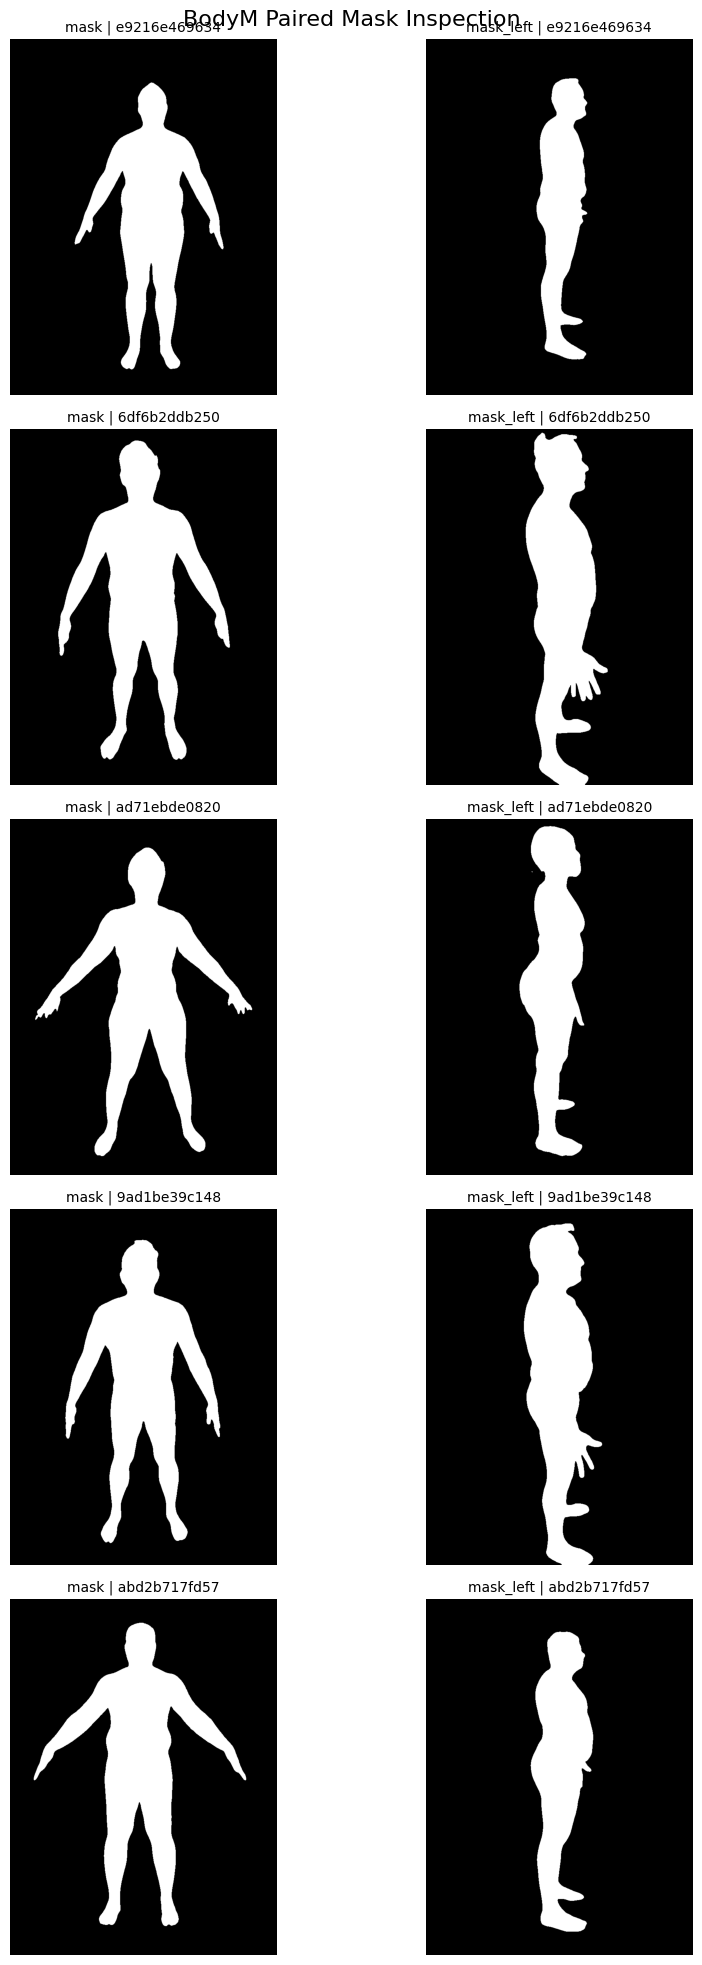


VISUAL INSPECTION COMPLETED


In [16]:

# TASK 2.10: Visual Verification of Paired Mask Images

import os
import boto3
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from PIL import Image
from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()
BUCKET_NAME = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

metadata_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

mapping = pd.read_csv(
    os.path.join(
        metadata_dir,
        "train_subject_to_photo_map.csv"
    )
)

# Select one photo from each of five different subjects
subject_sample = (
    mapping.groupby("subject_id", group_keys=False)
    .head(1)
    .sample(n=5, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

print("=" * 65)
print("VISUAL INSPECTION: MASK vs MASK_LEFT")
print("=" * 65)

for i, row in subject_sample.iterrows():

    subject_id = row["subject_id"]
    photo_id = row["photo_id"]

    images = []

    for folder in ["mask", "mask_left"]:

        key = f"train/{folder}/{photo_id}.png"

        response = s3.get_object(
            Bucket=BUCKET_NAME,
            Key=key
        )

        image = Image.open(
            BytesIO(response["Body"].read())
        ).convert("L")

        images.append(image)

        axes[i, 0 if folder == "mask" else 1].imshow(
            image,
            cmap="gray"
        )

        axes[i, 0 if folder == "mask" else 1].set_title(
            f"{folder} | {photo_id[:12]}",
            fontsize=10
        )

        axes[i, 0 if folder == "mask" else 1].axis("off")

    print(
        f"Sample {i+1}: "
        f"Subject={subject_id[:15]}... | "
        f"Photo={photo_id}"
    )

plt.suptitle(
    "BodyM Paired Mask Inspection",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("\nVISUAL INSPECTION COMPLETED")


In [17]:

# TASK 2.12-A: Measurement Values and Height Consistency Audit

import os
import numpy as np
import pandas as pd

PROJECT_ROOT = _dj_root()

metadata_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

splits = ["train", "testA", "testB"]

targets = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

report_rows = []

print("=" * 75)
print("DORJIBARI - MEASUREMENT VALUES AND HEIGHT AUDIT")
print("=" * 75)

for split in splits:

    print(f"\n{'=' * 60}")
    print("SPLIT:", split)
    print("=" * 60)

    measurements = pd.read_csv(
        os.path.join(
            metadata_dir,
            f"{split}_measurements.csv"
        )
    )

    hwg = pd.read_csv(
        os.path.join(
            metadata_dir,
            f"{split}_hwg_metadata.csv"
        )
    )

    # Merge only for comparison, without changing source CSVs
    merged = measurements[
        ["subject_id", "height"]
    ].merge(
        hwg[["subject_id", "height_cm"]],
        on="subject_id",
        how="inner",
        validate="one_to_one"
    )

    height_diff = (
        merged["height"] - merged["height_cm"]
    )

    print("\n[HEIGHT CONSISTENCY]")
    print("Matched subjects:", len(merged))
    print("Exact equal values:", (height_diff == 0).sum())
    print("Mean absolute difference:",
          round(height_diff.abs().mean(), 4))
    print("Maximum absolute difference:",
          round(height_diff.abs().max(), 4))
    print("Correlation:",
          round(merged["height"].corr(merged["height_cm"]), 6))

    print("\nHeight comparison sample:")
    print(merged.head(10).to_string(index=False))

    print("\n[TARGET MEASUREMENT SUMMARY]")

    for col in targets:

        values = pd.to_numeric(
            measurements[col],
            errors="coerce"
        )

        stats = {
            "split": split,
            "measurement": col,
            "count": values.count(),
            "missing": values.isna().sum(),
            "min": values.min(),
            "q1": values.quantile(0.25),
            "median": values.median(),
            "mean": values.mean(),
            "q3": values.quantile(0.75),
            "max": values.max(),
            "std": values.std()
        }

        report_rows.append(stats)

        print(f"\n{col}")
        print("Count:", stats["count"])
        print("Missing:", stats["missing"])
        print("Min:", round(stats["min"], 3))
        print("Q1:", round(stats["q1"], 3))
        print("Median:", round(stats["median"], 3))
        print("Mean:", round(stats["mean"], 3))
        print("Q3:", round(stats["q3"], 3))
        print("Max:", round(stats["max"], 3))
        print("Std:", round(stats["std"], 3))

    # Height summary
    print("\n[HEIGHT VALUE RANGES]")
    print("measurement height:")
    print(measurements["height"].describe().round(3).to_string())

    print("\nhwg height_cm:")
    print(hwg["height_cm"].describe().round(3).to_string())

# Save descriptive statistics
report = pd.DataFrame(report_rows)

report_path = os.path.join(
    metadata_dir,
    "measurement_values_audit.csv"
)

report.to_csv(report_path, index=False)

print("\n" + "=" * 75)
print("AUDIT SUMMARY")
print("=" * 75)

print(report.round(3).to_string(index=False))

print("\nSaved report:", report_path)
print("\nMEASUREMENT VALUES AUDIT COMPLETED")


DORJIBARI - MEASUREMENT VALUES AND HEIGHT AUDIT

SPLIT: train

[HEIGHT CONSISTENCY]
Matched subjects: 2018
Exact equal values: 0
Mean absolute difference: 1.3719
Maximum absolute difference: 22.8542
Correlation: 0.986008

Height comparison sample:
                                 subject_id     height  height_cm
-494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg 177.610992      178.0
-5OHO2b5mRDY1rvAf07sYYtekEEX7ViEGmvRr7l4tfc 164.379623      163.0
-5iHTazqnmWBsnUY6ymoCw1kORMymRDaUla1eNOjgvI 183.718842      185.0
-60o95b9oEE83BDV3GpsAVPA4TFvxuPPqtXEY5PApy8 169.059113      166.0
-67TrwlJ3GSsqPeHaa2Nb0iQ-BKZfIx4ERysQPZ0-SY 146.516632      144.6
-9Xvu9djN0oqidP9sUUQ-DZ6A0_upIBwARnNv7KTH3o 176.664841      177.0
-BdVKIwm3OGEfAEB56ar_HJqpYwmLXwhKKlyF0Gi4iU 178.977982      178.6
-CQBOT5zSJk5ZYlZ4cgBP2x4lzzLLdPC6sIbhUHYddI 160.164902      158.0
-ENkfo777FGDxVRXMHmkujRtZle23u0_smgNc2pQuUY 162.006592      162.0
-EujjqWPZ_L0NO_RqgxJ79mA23Tjj33cYAoFaysL4I0 155.545746      154.1

[TARGET MEASUREMENT SUMMA

In [18]:

# TASK 2.12-B: Investigate Height Discrepancies

import os
import numpy as np
import pandas as pd

PROJECT_ROOT = _dj_root()

metadata_dir = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

splits = ["train", "testA", "testB"]

all_discrepancies = []

print("=" * 75)
print("DORJIBARI - HEIGHT DISCREPANCY INVESTIGATION")
print("=" * 75)

for split in splits:

    measurements = pd.read_csv(
        os.path.join(metadata_dir, f"{split}_measurements.csv")
    )

    hwg = pd.read_csv(
        os.path.join(metadata_dir, f"{split}_hwg_metadata.csv")
    )

    merged = measurements[
        ["subject_id", "height"]
    ].merge(
        hwg[["subject_id", "height_cm"]],
        on="subject_id",
        how="inner",
        validate="one_to_one"
    )

    merged["split"] = split
    merged["signed_difference_cm"] = (
        merged["height"] - merged["height_cm"]
    )
    merged["absolute_difference_cm"] = (
        merged["signed_difference_cm"].abs()
    )

    all_discrepancies.append(merged)

    print(f"\n{'=' * 55}")
    print("SPLIT:", split)
    print("=" * 55)

    diff = merged["absolute_difference_cm"]

    print("\n[ABSOLUTE DIFFERENCE DISTRIBUTION]")
    print(diff.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(4).to_string())

    print("\n[THRESHOLD COUNTS]")

    for threshold in [2, 5, 10]:
        count = (diff > threshold).sum()
        percentage = count / len(diff) * 100

        print(
            f"Difference > {threshold} cm: "
            f"{count} subjects ({percentage:.2f}%)"
        )

    print("\n[SIGNED DIFFERENCE]")
    print(
        merged["signed_difference_cm"]
        .describe()
        .round(4)
        .to_string()
    )

    print("\n[10 LARGEST DISCREPANCIES]")

    largest = merged.nlargest(
        10, "absolute_difference_cm"
    )

    print(
        largest[
            [
                "subject_id",
                "height",
                "height_cm",
                "signed_difference_cm",
                "absolute_difference_cm"
            ]
        ].to_string(index=False)
    )

# Combine all splits
combined = pd.concat(
    all_discrepancies,
    ignore_index=True
)

output_path = os.path.join(
    metadata_dir,
    "height_discrepancy_audit.csv"
)

combined.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("OVERALL HEIGHT DISCREPANCY SUMMARY")
print("=" * 75)

print(
    combined.groupby("split")[
        "absolute_difference_cm"
    ].agg(
        ["count", "mean", "median", "max"]
    ).round(4).to_string()
)

print("\nTotal subjects:", len(combined))
print("Saved:", output_path)
print("\nHEIGHT DISCREPANCY INVESTIGATION COMPLETED")


DORJIBARI - HEIGHT DISCREPANCY INVESTIGATION

SPLIT: train

[ABSOLUTE DIFFERENCE DISTRIBUTION]
count    2018.0000
mean        1.3719
std         1.2168
min         0.0006
50%         1.1392
75%         1.9425
90%         2.8258
95%         3.3326
99%         4.6749
max        22.8542

[THRESHOLD COUNTS]
Difference > 2 cm: 480 subjects (23.79%)
Difference > 5 cm: 13 subjects (0.64%)
Difference > 10 cm: 3 subjects (0.15%)

[SIGNED DIFFERENCE]
count    2018.0000
mean        0.9298
std         1.5808
min       -22.8542
25%        -0.0291
50%         0.8919
75%         1.8775
max        14.2707

[10 LARGEST DISCREPANCIES]
                                 subject_id     height  height_cm  signed_difference_cm  absolute_difference_cm
jZSnwhgdKrST_LKPrB_mkjQ15fZqihhPOuMmXtQPGlM 163.545807      186.4            -22.854193               22.854193
s7ogioDf1U8mqqsD7r99clapeOQQfyr55h2X3ap3XJE 179.270691      165.0             14.270691               14.270691
H96X3Mk2kr5Ok54Lck9oR93rz2WR7maI1yuww5V

In [19]:

# TASK 2.12-C: Document BodyM Research Field Mapping

import os
from datetime import date

PROJECT_ROOT = _dj_root()

metadata_dir = os.path.join(
    PROJECT_ROOT,
    "dataset",
    "BodyM",
    "metadata"
)

os.makedirs(metadata_dir, exist_ok=True)

content = """# BodyM Research Field Mapping
## DorjiBari Dataset Audit

Audit date: 2026-11-19

## Dataset Sources

Dataset: Amazon BodyM
Official dataset documentation:
https://registry.opendata.aws/bodym/

Original research paper:
Human Body Measurement Estimation with Adversarial Augmentation

## Model Input

| CSV | Column | Meaning | Unit | Status |
|---|---|---|---|---|
| hwg_metadata.csv | height_cm | Subject stature | cm | Candidate input |

## Target Measurements

Source: measurements.csv

| Column | Meaning | Unit |
|---|---|---|
| chest | Chest girth | cm |
| waist | Waist girth | cm |
| hip | Hip girth | cm |
| shoulder-breadth | Shoulder breadth | cm |
| arm-length | Arm length | cm |

## Height Field Distinction

The BodyM paper describes subject height separately from
14 mesh-derived measurements.

The paper lists head-to-heel length among the 14
mesh-derived measurements.

The measurements.csv field named "height" is therefore
a candidate mapping to head-to-heel length. This mapping
requires source-schema confirmation.

The hwg_metadata.csv field "height_cm" is treated as
subject stature and is the candidate model input.

The two fields must not be treated as interchangeable.

## Research Restrictions

1. Do not overwrite original CSV files.
2. Do not silently replace one height field with another.
3. Do not use measurements.height as a model input.
4. Do not use TestA or TestB for model training or tuning.
5. Preserve subject-level separation.
6. Keep all five target measurements in centimetres.
7. Investigate unusual values before deciding whether
   any observation should be excluded.

## Current Status

Five target columns have no missing values in the
audited splits.

Height discrepancy investigation completed.

Exact source-schema mapping of measurements.height
remains to be confirmed.
"""

output_path = os.path.join(
    metadata_dir,
    "research_field_mapping.md"
)

with open(output_path, "w", encoding="utf-8") as f:
    f.write(content)

print("=" * 65)
print("RESEARCH FIELD MAPPING DOCUMENT")
print("=" * 65)
print("Saved:", output_path)
print("File exists:", os.path.exists(output_path))
print("File size:", os.path.getsize(output_path), "bytes")
print("\nDOCUMENTATION CREATED SUCCESSFULLY")


RESEARCH FIELD MAPPING DOCUMENT
Saved: /content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/metadata/research_field_mapping.md
File exists: True
File size: 1826 bytes

DOCUMENTATION CREATED SUCCESSFULLY


In [20]:

# TASK 2.13-A: Target Measurement Outlier Investigation

import os
import numpy as np
import pandas as pd

PROJECT_ROOT = _dj_root()

METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

IQR_MULTIPLIER = 1.5
ROBUST_Z_THRESHOLD = 3.5

summary_rows = []
candidate_rows = []

print("=" * 75)
print("DORJIBARI - TARGET MEASUREMENT OUTLIER INVESTIGATION")
print("=" * 75)

for split in SPLITS:

    file_path = os.path.join(
        METADATA_DIR,
        f"{split}_measurements.csv"
    )

    df = pd.read_csv(file_path)

    print(f"\nSPLIT: {split}")
    print("-" * 75)

    for target in TARGETS:

        values = pd.to_numeric(
            df[target], errors="coerce"
        )

        valid = values.dropna()

        q1 = valid.quantile(0.25)
        median = valid.median()
        q3 = valid.quantile(0.75)

        iqr = q3 - q1

        lower_fence = q1 - IQR_MULTIPLIER * iqr
        upper_fence = q3 + IQR_MULTIPLIER * iqr

        mad = (valid - median).abs().median()

        if mad > 0:
            robust_z = 0.67448975 * (values - median) / mad
        else:
            robust_z = pd.Series(
                np.zeros(len(values)),
                index=values.index
            )

        iqr_flag = (
            (values < lower_fence) |
            (values > upper_fence)
        )

        robust_flag = robust_z.abs() > ROBUST_Z_THRESHOLD

        candidate_flag = iqr_flag | robust_flag

        iqr_count = int(iqr_flag.sum())
        robust_count = int(robust_flag.sum())
        combined_count = int(candidate_flag.sum())

        summary_rows.append({
            "split": split,
            "measurement": target,
            "sample_count": len(valid),
            "min": valid.min(),
            "q1": q1,
            "median": median,
            "q3": q3,
            "max": valid.max(),
            "iqr": iqr,
            "lower_iqr_fence": lower_fence,
            "upper_iqr_fence": upper_fence,
            "iqr_candidates": iqr_count,
            "robust_z_candidates": robust_count,
            "combined_candidates": combined_count
        })

        for idx in df.index[candidate_flag.fillna(False)]:

            candidate_rows.append({
                "split": split,
                "subject_id": df.loc[idx, "subject_id"],
                "measurement": target,
                "value_cm": values.loc[idx],
                "robust_z_score": robust_z.loc[idx],
                "iqr_flag": bool(iqr_flag.loc[idx]),
                "robust_z_flag": bool(robust_flag.loc[idx]),
                "lower_iqr_fence": lower_fence,
                "upper_iqr_fence": upper_fence
            })

        print(
            f"{target:20s} | "
            f"IQR: {iqr_count:4d} | "
            f"Robust Z: {robust_count:4d} | "
            f"Combined: {combined_count:4d}"
        )

# Create DataFrames
summary_df = pd.DataFrame(summary_rows)
candidates_df = pd.DataFrame(candidate_rows)

# Save reports
summary_path = os.path.join(
    METADATA_DIR,
    "outlier_summary.csv"
)

candidates_path = os.path.join(
    METADATA_DIR,
    "outlier_candidates.csv"
)

summary_df.to_csv(summary_path, index=False)
candidates_df.to_csv(candidates_path, index=False)

print("\n" + "=" * 75)
print("OUTLIER INVESTIGATION SUMMARY")
print("=" * 75)

print("Total split-measurement combinations:", len(summary_df))
print("Total candidate records:", len(candidates_df))

print("\nCandidates by split:")
if len(candidates_df) > 0:
    print(
        candidates_df.groupby("split")
        .size()
        .to_string()
    )
else:
    print("No candidate records detected.")

print("\nSaved reports:")
print("1.", summary_path)
print("2.", candidates_path)

print("\nOUTLIER INVESTIGATION COMPLETED")
print("NOTE: No observations were removed or modified.")


DORJIBARI - TARGET MEASUREMENT OUTLIER INVESTIGATION

SPLIT: train
---------------------------------------------------------------------------
chest                | IQR:   33 | Robust Z:   10 | Combined:   33
waist                | IQR:   35 | Robust Z:   10 | Combined:   35
hip                  | IQR:   63 | Robust Z:   28 | Combined:   63
shoulder-breadth     | IQR:    0 | Robust Z:    0 | Combined:    0
arm-length           | IQR:   10 | Robust Z:    0 | Combined:   10

SPLIT: testA
---------------------------------------------------------------------------
chest                | IQR:    3 | Robust Z:    1 | Combined:    3
waist                | IQR:    4 | Robust Z:    3 | Combined:    4
hip                  | IQR:    4 | Robust Z:    3 | Combined:    4
shoulder-breadth     | IQR:    0 | Robust Z:    0 | Combined:    0
arm-length           | IQR:    1 | Robust Z:    0 | Combined:    1

SPLIT: testB
---------------------------------------------------------------------------
chest  

In [21]:

# TASK 2.13-B: Review Extreme Outlier Candidates

import os
import numpy as np
import pandas as pd

PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

candidates_path = os.path.join(
    METADATA_DIR, "outlier_candidates.csv"
)

candidates = pd.read_csv(candidates_path)

review_rows = []

print("=" * 75)
print("DORJIBARI - EXTREME CANDIDATE REVIEW")
print("=" * 75)

for split in SPLITS:

    measurements_path = os.path.join(
        METADATA_DIR,
        f"{split}_measurements.csv"
    )

    measurements = pd.read_csv(measurements_path)

    split_candidates = candidates[
        candidates["split"] == split
    ].copy()

    print(f"\nSPLIT: {split}")
    print("-" * 75)

    for target in TARGETS:

        group = split_candidates[
            split_candidates["measurement"] == target
        ].copy()

        if group.empty:
            print(f"\n{target}: No candidates")
            continue

        values = measurements[target].dropna()

        median = values.median()
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        group["median_cm"] = median
        group["q1_cm"] = q1
        group["q3_cm"] = q3

        if iqr > 0:
            group["distance_from_median_iqr"] = (
                (group["value_cm"] - median).abs() / iqr
            )
        else:
            group["distance_from_median_iqr"] = np.nan

        group["direction"] = np.where(
            group["value_cm"] < median,
            "LOW",
            "HIGH"
        )

        group = group.sort_values(
            "distance_from_median_iqr",
            ascending=False
        )

        print(
            f"\n{target} | Candidates: {len(group)} "
            f"| Unique subjects: {group['subject_id'].nunique()}"
        )

        # Show five lowest and five highest candidate values
        lowest = group.nsmallest(5, "value_cm")
        highest = group.nlargest(5, "value_cm")

        selected = pd.concat([lowest, highest]).drop_duplicates(
            subset=["subject_id", "measurement"]
        )

        print("Most extreme LOW/HIGH values:")

        for _, row in selected.iterrows():

            print(
                f"  Subject: {row['subject_id']} | "
                f"Value: {row['value_cm']:.3f} cm | "
                f"Median: {median:.3f} cm | "
                f"Direction: {row['direction']} | "
                f"IQR distance: "
                f"{row['distance_from_median_iqr']:.2f}"
            )

        review_rows.extend(
            group.to_dict(orient="records")
        )

review_df = pd.DataFrame(review_rows)

review_path = os.path.join(
    METADATA_DIR,
    "outlier_candidate_review.csv"
)

review_df.to_csv(review_path, index=False)

print("\n" + "=" * 75)
print("CANDIDATE REVIEW COMPLETED")
print("=" * 75)

print("Reviewed candidate records:", len(review_df))
print("Unique subjects across split-measurement records:",
      review_df[["split", "subject_id"]].drop_duplicates().shape[0])

print("Saved:", review_path)
print("File exists:", os.path.exists(review_path))

print("\nNo observations were removed or modified.")


DORJIBARI - EXTREME CANDIDATE REVIEW

SPLIT: train
---------------------------------------------------------------------------

chest | Candidates: 33 | Unique subjects: 33
Most extreme LOW/HIGH values:
  Subject: 59bc2765681516389ccf4551 | Value: 129.256 cm | Median: 101.162 cm | Direction: HIGH | IQR distance: 2.00
  Subject: rp_bxD01AdOZy0FS06mBgDSM5Dl6OnRh8IhfyUTeY04 | Value: 129.968 cm | Median: 101.162 cm | Direction: HIGH | IQR distance: 2.05
  Subject: qS2_LwZ498JjhCo8GH05WxJwGZ0obuoTjp3ZbGZEKWo | Value: 130.147 cm | Median: 101.162 cm | Direction: HIGH | IQR distance: 2.06
  Subject: UueDSYaaKwwE0UEq27l9nzA6p5xEn76jwy0yla549PI | Value: 130.231 cm | Median: 101.162 cm | Direction: HIGH | IQR distance: 2.07
  Subject: R6lI4XrZv80ND_JSygPq0gmxy-AJ3FqmuLPssZXEWrA | Value: 130.448 cm | Median: 101.162 cm | Direction: HIGH | IQR distance: 2.09
  Subject: 59bc275c681516389ccf41bf | Value: 153.941 cm | Median: 101.162 cm | Direction: HIGH | IQR distance: 3.76
  Subject: be8CgGUva4wFWA

In [22]:

# TASK 2.13-C: Cross-Measurement Subject-Level Investigation

import os
import pandas as pd

PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

candidate_path = os.path.join(
    METADATA_DIR, "outlier_candidates.csv"
)

candidates = pd.read_csv(candidate_path)

all_subject_reports = []

print("=" * 75)
print("SUBJECT-LEVEL CROSS-MEASUREMENT INVESTIGATION")
print("=" * 75)

for split in SPLITS:

    print(f"\nSPLIT: {split}")
    print("-" * 75)

    # Load original split-level files
    measurements = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_measurements.csv")
    )

    hwg = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_hwg_metadata.csv")
    )

    photo_map = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_subject_to_photo_map.csv")
    )

    split_candidates = candidates[
        candidates["split"] == split
    ].copy()

    if split_candidates.empty:
        print("No candidate subjects in this split.")
        continue

    # One row per subject, with all candidate measurements listed
    subject_flags = (
        split_candidates.groupby("subject_id")
        .agg(
            candidate_measurements=(
                "measurement",
                lambda x: ", ".join(sorted(set(x)))
            ),
            candidate_count=("measurement", "nunique")
        )
        .reset_index()
    )

    # Count the number of paired photos per subject
    photo_counts = (
        photo_map.groupby("subject_id")
        .size()
        .reset_index(name="photo_count")
    )

    # Merge subject-level information
    report = subject_flags.merge(
        measurements[["subject_id"] + TARGETS],
        on="subject_id",
        how="left",
        validate="one_to_one"
    )

    report = report.merge(
        hwg[["subject_id", "height_cm", "weight_kg"]],
        on="subject_id",
        how="left",
        validate="one_to_one"
    )

    report = report.merge(
        photo_counts,
        on="subject_id",
        how="left",
        validate="one_to_one"
    )

    report.insert(0, "split", split)

    all_subject_reports.append(report)

    print("Candidate subjects:", len(report))

    print("\nSubjects with multiple candidate measurements:")
    multi = report[report["candidate_count"] > 1]

    print("Count:", len(multi))

    if not multi.empty:
        print(
            multi[
                [
                    "subject_id",
                    "candidate_measurements",
                    "candidate_count",
                    "chest",
                    "waist",
                    "hip",
                    "shoulder-breadth",
                    "arm-length",
                    "height_cm",
                    "weight_kg",
                    "photo_count"
                ]
            ]
            .sort_values("candidate_count", ascending=False)
            .to_string(index=False)
        )

    print("\nCandidate count distribution:")
    print(
        report["candidate_count"]
        .value_counts()
        .sort_index()
        .to_string()
    )

# Combine all splits
final_report = pd.concat(
    all_subject_reports,
    ignore_index=True
)

output_path = os.path.join(
    METADATA_DIR,
    "subject_level_outlier_investigation.csv"
)

final_report.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("SUBJECT-LEVEL INVESTIGATION COMPLETED")
print("=" * 75)

print("Total split-specific subjects:", len(final_report))
print(
    "Subjects with multiple candidate measurements:",
    int((final_report["candidate_count"] > 1).sum())
)

print("Missing height values:", int(final_report["height_cm"].isna().sum()))
print("Missing weight values:", int(final_report["weight_kg"].isna().sum()))
print("Missing photo counts:", int(final_report["photo_count"].isna().sum()))

print("Saved:", output_path)
print("File exists:", os.path.exists(output_path))

print("\nOriginal dataset files were not modified.")
print("No observations were removed.")


SUBJECT-LEVEL CROSS-MEASUREMENT INVESTIGATION

SPLIT: train
---------------------------------------------------------------------------
Candidate subjects: 82

Subjects with multiple candidate measurements:
Count: 38
                                 subject_id candidate_measurements  candidate_count      chest      waist        hip  shoulder-breadth  arm-length  height_cm  weight_kg  photo_count
1obtJV-1XLXVJLmVLYfge5Q3Tj6KBWRz5lCerwj7hqQ      chest, hip, waist                3 149.625381 148.114258 149.687317         42.877552   55.442799     185.00     159.75           10
                   59bc2758681516389ccf4071      chest, hip, waist                3 148.795853 129.257294 145.555099         38.263977   47.604340     159.05     131.10            9
                   59bc275a681516389ccf40d8      chest, hip, waist                3 139.537704 123.228218 149.450073         37.489784   45.724220     156.65     124.70            5
8JjFTu3rC8kbvRBnU-bPDeDSrLxKghNWrntdXKv5FCw      chest,


SPLIT: train

Subject ID: Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU
Photo ID: 49e8f991af693b63836a077a636aa037
Height (cm): 178.95
Weight (kg): 181.9
chest: 148.443 cm
waist: 164.297 cm
hip: 166.852 cm
shoulder-breadth: 42.126 cm
arm-length: 50.282 cm

Subject ID: 59bc275c681516389ccf41bf
Photo ID: 4d17fb6a8d5754a1b740d75664b94035
Height (cm): 157.9
Weight (kg): 156.6
chest: 153.941 cm
waist: 146.972 cm
hip: 158.518 cm
shoulder-breadth: 38.021 cm
arm-length: 45.623 cm


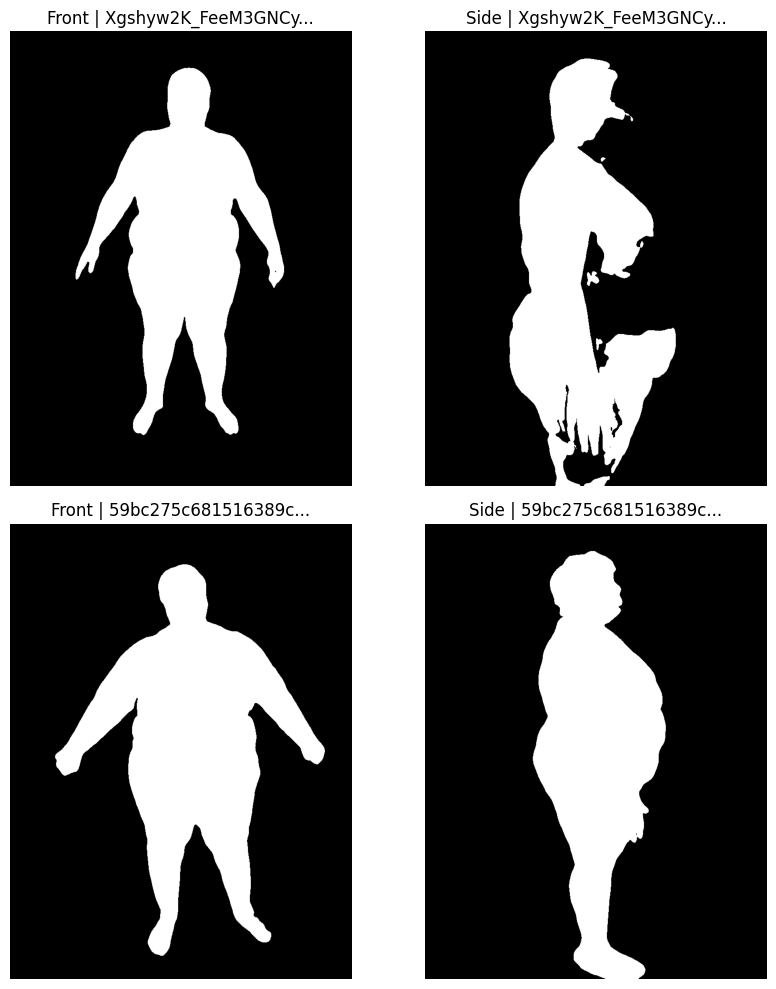


SPLIT: testA

Subject ID: 59bc275a681516389ccf40e1
Photo ID: 027727b5f7ac827caed03e932871d1aa
Height (cm): 172.1
Weight (kg): 111.1
chest: 134.907 cm
waist: 118.413 cm
hip: 132.089 cm
shoulder-breadth: 37.611 cm
arm-length: 51.359 cm

Subject ID: 59bc275c681516389ccf41b9
Photo ID: 00aefca158a6b773b8c466c9b715ac25
Height (cm): 172.5
Weight (kg): 111.5
chest: 127.580 cm
waist: 113.056 cm
hip: 128.207 cm
shoulder-breadth: 37.658 cm
arm-length: 51.966 cm


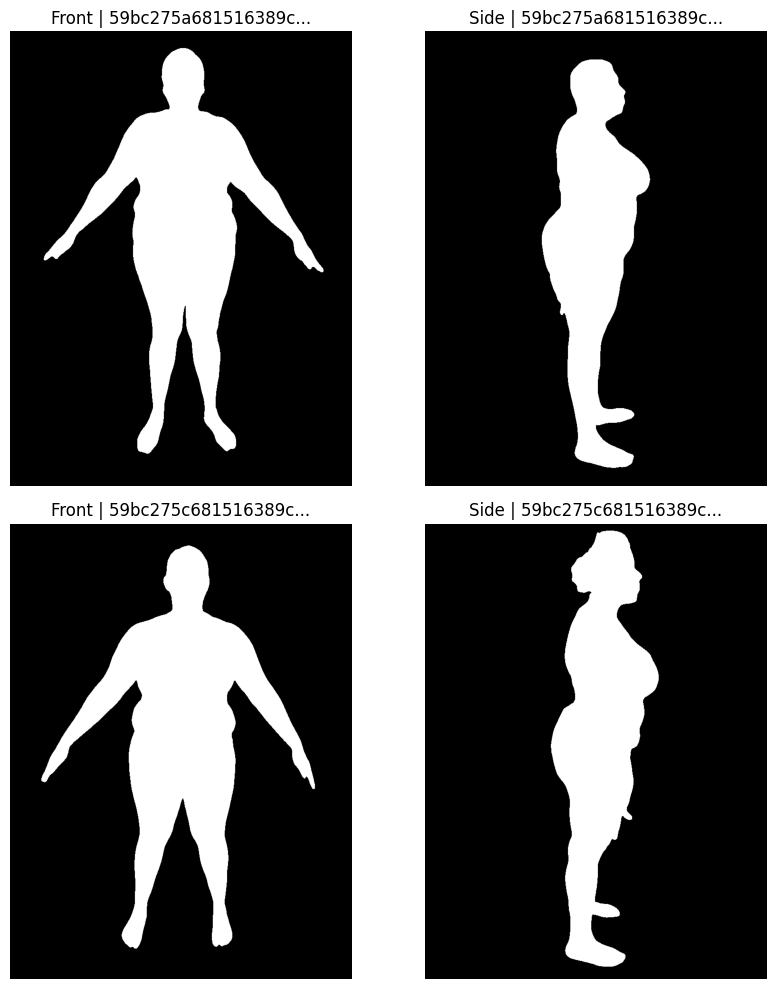


SPLIT: testB

Subject ID: 59bc275b681516389ccf4162
Photo ID: 8253201baa6337eb0ad4398bad1834a9
Height (cm): 164.0
Weight (kg): 127.9
chest: 158.098 cm
waist: 137.781 cm
hip: 136.508 cm
shoulder-breadth: 40.583 cm
arm-length: 48.036 cm

Subject ID: 3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA
Photo ID: 6b25639753d2cecde54f99523f675ccc
Height (cm): 176.0
Weight (kg): 129.5
chest: 139.678 cm
waist: 130.971 cm
hip: 132.311 cm
shoulder-breadth: 42.193 cm
arm-length: 48.455 cm


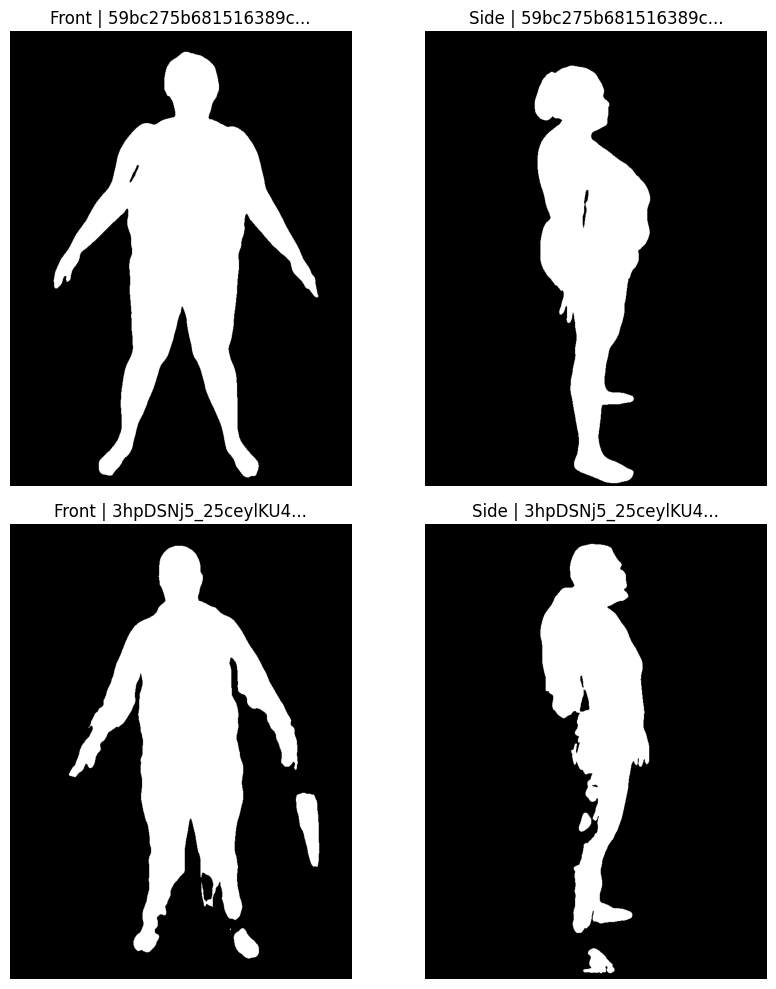


VISUAL INSPECTION SAMPLE COMPLETED
Subjects displayed: 6
No original files were modified.


In [23]:

# TASK 2.13-D: Visual Inspection of Selected Outlier Candidates

import boto3
from botocore import UNSIGNED
from botocore.config import Config
from io import BytesIO
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = _dj_root()
METADATA_DIR = f"{PROJECT_ROOT}/dataset/BodyM/metadata"

BUCKET_NAME = "amazon-bodym"

# Public AWS S3 connection
s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

# Representative subjects selected from the previous audit
SELECTED_SUBJECTS = {
    "train": [
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "59bc275c681516389ccf41bf"
    ],
    "testA": [
        "59bc275a681516389ccf40e1",
        "59bc275c681516389ccf41b9"
    ],
    "testB": [
        "59bc275b681516389ccf4162",
        "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA"
    ]
}

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

def load_s3_image(key):
    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    image = Image.open(
        BytesIO(response["Body"].read())
    )

    image.load()
    return image.convert("L")


total_displayed = 0

for split, subject_ids in SELECTED_SUBJECTS.items():

    print(f"\n{'=' * 70}")
    print(f"SPLIT: {split}")
    print("=" * 70)

    photo_map = pd.read_csv(
        f"{METADATA_DIR}/{split}_subject_to_photo_map.csv"
    )

    measurements = pd.read_csv(
        f"{METADATA_DIR}/{split}_measurements.csv"
    )

    hwg = pd.read_csv(
        f"{METADATA_DIR}/{split}_hwg_metadata.csv"
    )

    fig, axes = plt.subplots(
        len(subject_ids), 2,
        figsize=(9, 5 * len(subject_ids))
    )

    if len(subject_ids) == 1:
        axes = [axes]

    for row_idx, subject_id in enumerate(subject_ids):

        subject_photos = photo_map[
            photo_map["subject_id"] == subject_id
        ]

        if subject_photos.empty:
            print("WARNING: No photo mapping:", subject_id)
            continue

        # Use one deterministic photo for this subject
        photo_id = sorted(
            subject_photos["photo_id"].astype(str)
        )[0]

        front_key = f"{split}/mask/{photo_id}.png"
        side_key = f"{split}/mask_left/{photo_id}.png"

        front_image = load_s3_image(front_key)
        side_image = load_s3_image(side_key)

        axes[row_idx][0].imshow(
            front_image, cmap="gray"
        )
        axes[row_idx][0].set_title(
            f"Front | {subject_id[:18]}..."
        )
        axes[row_idx][0].axis("off")

        axes[row_idx][1].imshow(
            side_image, cmap="gray"
        )
        axes[row_idx][1].set_title(
            f"Side | {subject_id[:18]}..."
        )
        axes[row_idx][1].axis("off")

        measurement_row = measurements[
            measurements["subject_id"] == subject_id
        ].iloc[0]

        hwg_row = hwg[
            hwg["subject_id"] == subject_id
        ].iloc[0]

        print(f"\nSubject ID: {subject_id}")
        print("Photo ID:", photo_id)
        print("Height (cm):", hwg_row["height_cm"])
        print("Weight (kg):", hwg_row["weight_kg"])

        for target in TARGETS:
            print(
                f"{target}: "
                f"{measurement_row[target]:.3f} cm"
            )

        total_displayed += 1

    plt.tight_layout()
    plt.show()

print("\n" + "=" * 70)
print("VISUAL INSPECTION SAMPLE COMPLETED")
print("Subjects displayed:", total_displayed)
print("No original files were modified.")



SPLIT: train
SUBJECT: Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU
Total available photo pairs: 7
Photo 1: 49e8f991af693b63836a077a636aa037 | LOADED
Photo 2: 5e4072c0700d2208c71ffcfc753e13bd | LOADED
Photo 3: 60a29701e0b9ab2accb0bff44676a57b | LOADED
Photo 4: 60a760f1b45a84eebbfb4c0b4080139e | LOADED
Photo 5: 8ae9aed074c4c49bfcf2f0faeede7270 | LOADED
Photo 6: 95c9649da7ec2719e3b86d5b9948850b | LOADED
Photo 7: d8b3ce9af9d8bd3707200135ff9cdd8a | LOADED


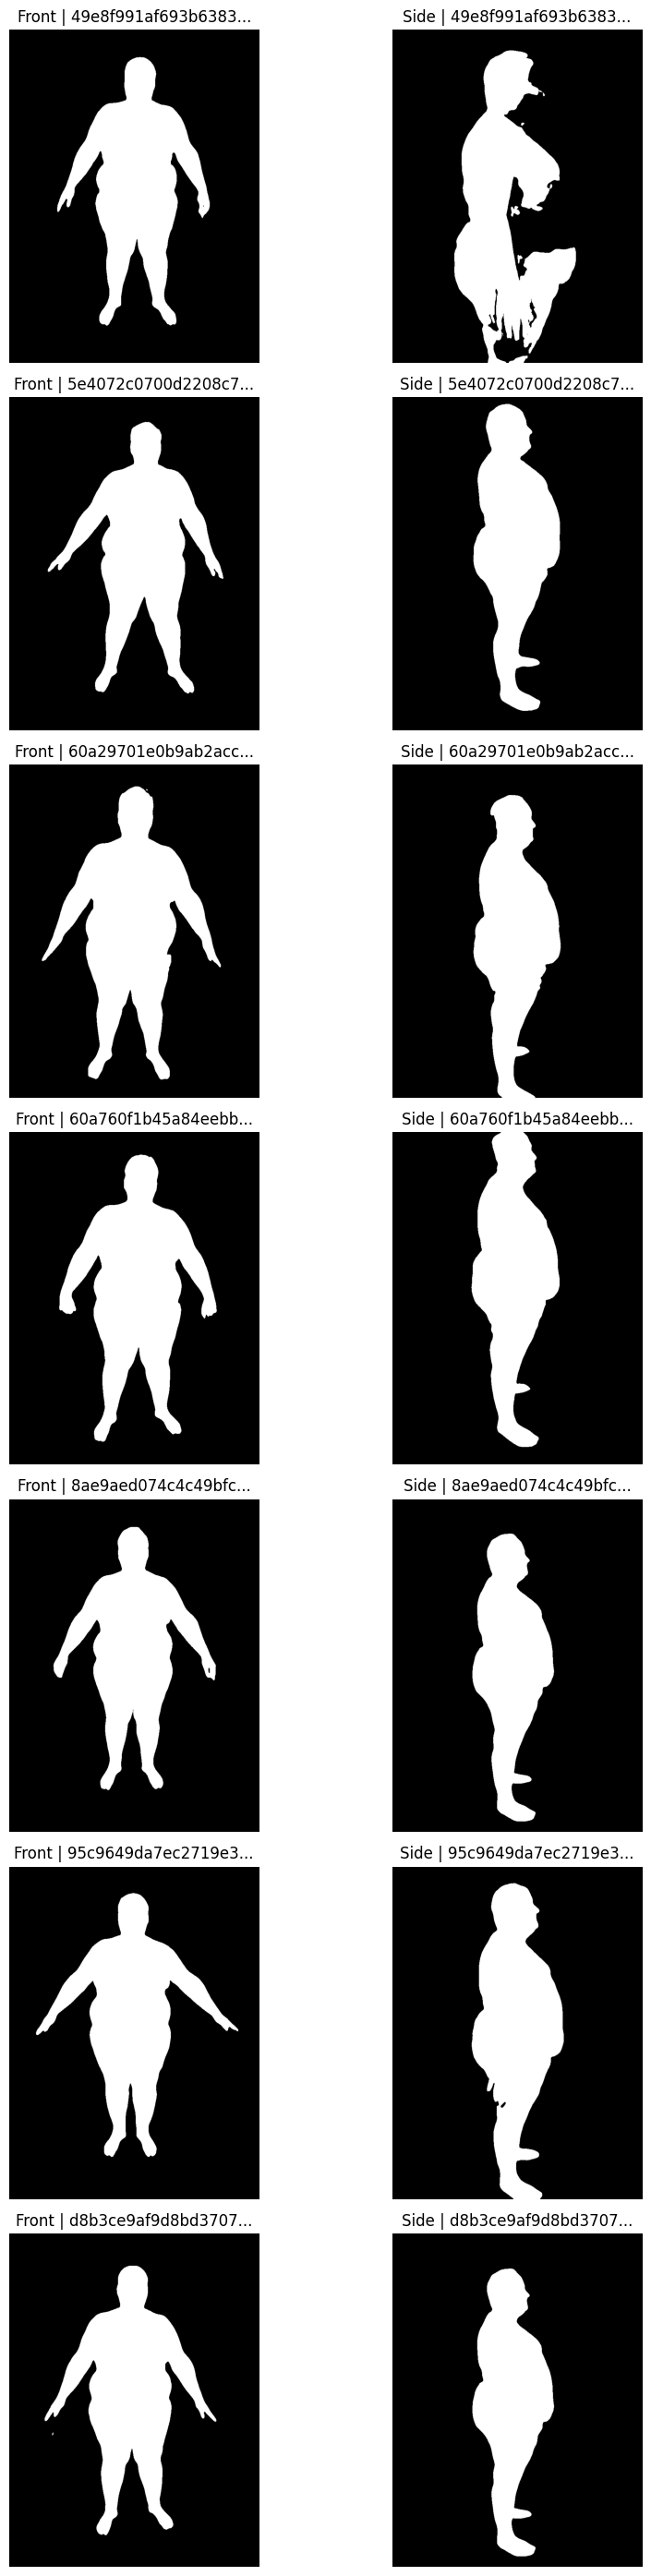


SPLIT: testB
SUBJECT: 3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA
Total available photo pairs: 3
Photo 1: 6b25639753d2cecde54f99523f675ccc | LOADED
Photo 2: 9a685a95bdbc4e24bf7b6e7653b4aa17 | LOADED
Photo 3: d5cc73027431175b7b4e4217b7ff56dd | LOADED


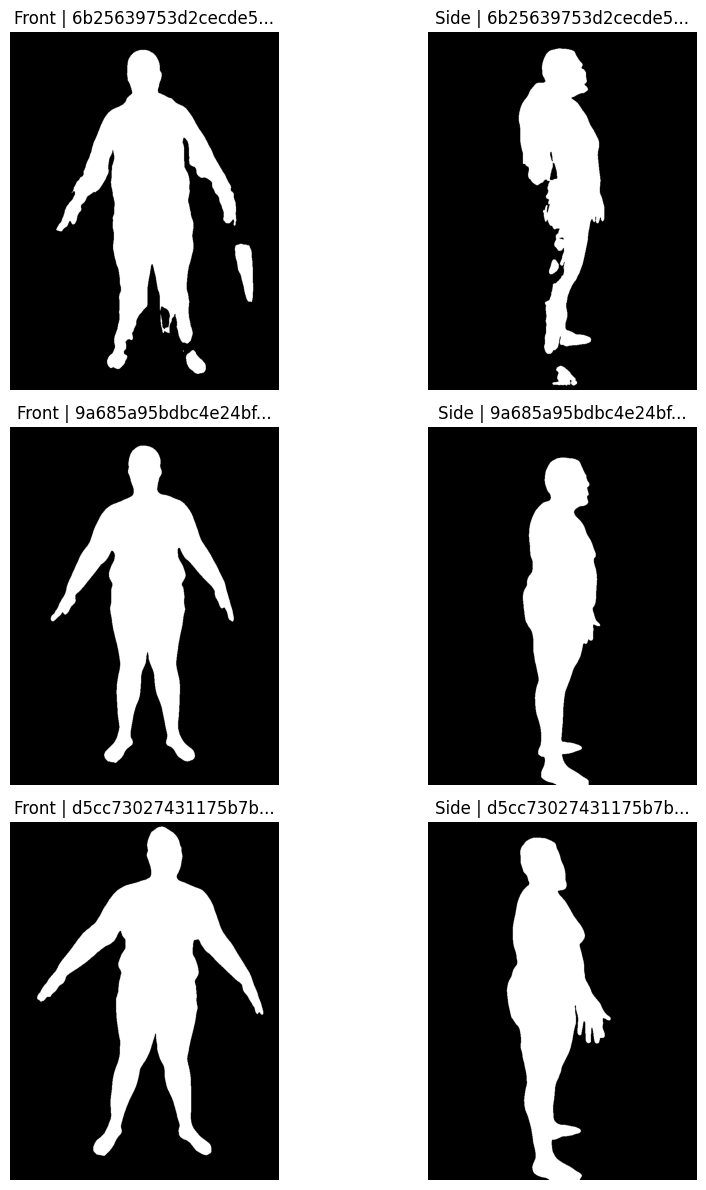


ALL-PHOTO VISUAL INSPECTION COMPLETED
No original files were modified.


In [24]:

import os
import boto3
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config
from IPython.display import display

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

BUCKET_NAME = "amazon-bodym"

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

subjects_to_inspect = [
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU"
    },
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA"
    }
]

# --------------------------------------------------
# 2. Download helper
# --------------------------------------------------
def load_s3_image(key):
    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )
    return Image.open(
        BytesIO(response["Body"].read())
    ).convert("L")

# --------------------------------------------------
# 3. Inspect all photo pairs
# --------------------------------------------------
for item in subjects_to_inspect:

    split = item["split"]
    subject_id = item["subject_id"]

    print("\n" + "=" * 75)
    print(f"SPLIT: {split}")
    print(f"SUBJECT: {subject_id}")

    mapping_path = os.path.join(
        METADATA_DIR,
        f"{split}_subject_to_photo_map.csv"
    )

    mapping_df = pd.read_csv(mapping_path)

    subject_photos = mapping_df.loc[
        mapping_df["subject_id"] == subject_id,
        "photo_id"
    ].astype(str).sort_values().tolist()

    print("Total available photo pairs:", len(subject_photos))

    if not subject_photos:
        print("WARNING: No photos found for this subject.")
        continue

    fig, axes = plt.subplots(
        len(subject_photos), 2,
        figsize=(10, 4 * len(subject_photos)),
        squeeze=False
    )

    for idx, photo_id in enumerate(subject_photos):

        front_key = f"{split}/mask/{photo_id}.png"
        side_key = f"{split}/mask_left/{photo_id}.png"

        try:
            front_img = load_s3_image(front_key)
            side_img = load_s3_image(side_key)

            axes[idx][0].imshow(front_img, cmap="gray")
            axes[idx][0].set_title(
                f"Front | {photo_id[:18]}..."
            )
            axes[idx][0].axis("off")

            axes[idx][1].imshow(side_img, cmap="gray")
            axes[idx][1].set_title(
                f"Side | {photo_id[:18]}..."
            )
            axes[idx][1].axis("off")

            print(f"Photo {idx + 1}: {photo_id} | LOADED")

        except Exception as e:
            axes[idx][0].axis("off")
            axes[idx][1].axis("off")
            print(f"Photo {idx + 1}: {photo_id} | ERROR: {e}")

    plt.tight_layout()
    plt.show()

print("\nALL-PHOTO VISUAL INSPECTION COMPLETED")
print("No original files were modified.")


In [25]:

import os
import pandas as pd

PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

# Screenshot থেকে পাওয়া photo ID prefixes
problematic_items = [
    {
        "prefix": "6b25639753d2cecde5",
        "view": "front",
        "issue": "Large detached foreground component",
        "severity": "High"
    },
    {
        "prefix": "49e8f991af693b6383",
        "view": "side",
        "issue": "Large irregular foreground region",
        "severity": "High"
    },
    {
        "prefix": "6b25639753d2cecde5",
        "view": "side",
        "issue": "Detached foreground component below feet",
        "severity": "Medium"
    }
]

splits = ["train", "testA", "testB"]
mapping_data = {}

# Load mappings
for split in splits:
    path = os.path.join(
        METADATA_DIR,
        f"{split}_subject_to_photo_map.csv"
    )
    mapping_data[split] = pd.read_csv(path, dtype=str)

audit_rows = []

# Resolve full photo IDs
for item in problematic_items:

    matches = []

    for split, mapping_df in mapping_data.items():
        matched = mapping_df[
            mapping_df["photo_id"].str.startswith(item["prefix"])
        ]

        for _, row in matched.iterrows():
            matches.append({
                "split": split,
                "subject_id": row["subject_id"],
                "photo_id": row["photo_id"]
            })

    print("\nPrefix:", item["prefix"])
    print("View:", item["view"])
    print("Matches:", len(matches))

    for match in matches:
        print(match)

    if len(matches) != 1:
        print("WARNING: Expected exactly one match. Not added.")
        continue

    match = matches[0]

    audit_rows.append({
        "split": match["split"],
        "subject_id": match["subject_id"],
        "photo_id": match["photo_id"],
        "view": item["view"],
        "issue": item["issue"],
        "severity": item["severity"],
        "decision": "Flagged - pending review",
        "removed_from_dataset": False
    })

# Save audit report
audit_df = pd.DataFrame(audit_rows)

output_path = os.path.join(
    METADATA_DIR,
    "problematic_image_audit.csv"
)

if len(audit_df) == len(problematic_items):
    audit_df.to_csv(output_path, index=False)

    print("\n" + "=" * 65)
    print("PROBLEMATIC IMAGE AUDIT")
    print("=" * 65)
    display(audit_df)

    print("\nSaved:", output_path)
    print("Total flagged masks:", len(audit_df))
    print("Unique photo IDs:", audit_df["photo_id"].nunique())
    print("Unique subjects:", audit_df["subject_id"].nunique())
    print("Removed images: 0")
else:
    print("\nAudit CSV NOT saved.")
    print("Some photo IDs could not be uniquely resolved.")
    print("Please review the matching output above.")



Prefix: 6b25639753d2cecde5
View: front
Matches: 1
{'split': 'testB', 'subject_id': '3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA', 'photo_id': '6b25639753d2cecde54f99523f675ccc'}

Prefix: 49e8f991af693b6383
View: side
Matches: 1
{'split': 'train', 'subject_id': 'Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU', 'photo_id': '49e8f991af693b63836a077a636aa037'}

Prefix: 6b25639753d2cecde5
View: side
Matches: 1
{'split': 'testB', 'subject_id': '3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA', 'photo_id': '6b25639753d2cecde54f99523f675ccc'}

PROBLEMATIC IMAGE AUDIT


,split,subject_id,photo_id,view,issue,severity,decision,removed_from_dataset
0,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,6b25639753d2cecde54f99523f675ccc,front,Large detached foreground component,High,Flagged - pending review,False
1,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,49e8f991af693b63836a077a636aa037,side,Large irregular foreground region,High,Flagged - pending review,False
2,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,6b25639753d2cecde54f99523f675ccc,side,Detached foreground component below feet,Medium,Flagged - pending review,False



Saved: /content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/metadata/problematic_image_audit.csv
Total flagged masks: 3
Unique photo IDs: 2
Unique subjects: 2
Removed images: 0


In [26]:

import os
import pandas as pd

PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

affected_subjects = [
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "flagged_photo_id": "6b25639753d2cecde54f99523f675ccc"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "flagged_photo_id": "49e8f991af693b63836a077a636aa037"
    }
]

results = []

for item in affected_subjects:

    split = item["split"]
    subject_id = item["subject_id"]
    flagged_id = item["flagged_photo_id"]

    mapping_path = os.path.join(
        METADATA_DIR,
        f"{split}_subject_to_photo_map.csv"
    )

    df = pd.read_csv(mapping_path, dtype=str)

    subject_photos = sorted(
        df.loc[
            df["subject_id"] == subject_id,
            "photo_id"
        ].tolist()
    )

    alternatives = [
        photo_id for photo_id in subject_photos
        if photo_id != flagged_id
    ]

    print("\n" + "=" * 70)
    print("SPLIT:", split)
    print("SUBJECT:", subject_id)
    print("Total photo pairs:", len(subject_photos))
    print("Flagged photo ID:", flagged_id)
    print("Alternative photo pairs:", len(alternatives))

    for idx, photo_id in enumerate(alternatives, 1):
        print(f"Alternative {idx}: {photo_id}")

    results.append({
        "split": split,
        "subject_id": subject_id,
        "total_photo_pairs": len(subject_photos),
        "flagged_photo_pairs": 1,
        "alternative_photo_pairs": len(alternatives),
        "alternative_photo_ids": ";".join(alternatives)
    })

impact_df = pd.DataFrame(results)

output_path = os.path.join(
    METADATA_DIR,
    "affected_subject_impact.csv"
)

impact_df.to_csv(output_path, index=False)

print("\n" + "=" * 70)
print("AFFECTED SUBJECT IMPACT SUMMARY")
display(impact_df)

print("Saved:", output_path)



SPLIT: testB
SUBJECT: 3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA
Total photo pairs: 3
Flagged photo ID: 6b25639753d2cecde54f99523f675ccc
Alternative photo pairs: 2
Alternative 1: 9a685a95bdbc4e24bf7b6e7653b4aa17
Alternative 2: d5cc73027431175b7b4e4217b7ff56dd

SPLIT: train
SUBJECT: Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU
Total photo pairs: 7
Flagged photo ID: 49e8f991af693b63836a077a636aa037
Alternative photo pairs: 6
Alternative 1: 5e4072c0700d2208c71ffcfc753e13bd
Alternative 2: 60a29701e0b9ab2accb0bff44676a57b
Alternative 3: 60a760f1b45a84eebbfb4c0b4080139e
Alternative 4: 8ae9aed074c4c49bfcf2f0faeede7270
Alternative 5: 95c9649da7ec2719e3b86d5b9948850b
Alternative 6: d8b3ce9af9d8bd3707200135ff9cdd8a

AFFECTED SUBJECT IMPACT SUMMARY


,split,subject_id,total_photo_pairs,flagged_photo_pairs,alternative_photo_pairs,alternative_photo_ids
0,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,3,1,2,9a685a95bdbc4e24bf7b6e7653b4aa17;d5cc730274311...
1,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,7,1,6,5e4072c0700d2208c71ffcfc753e13bd;60a29701e0b9a...


Saved: /content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/metadata/affected_subject_impact.csv


Total alternative pairs: 8
1. testB | 9a685a95bdbc4e24bf7b6e7653b4aa17 | LOADED
2. testB | d5cc73027431175b7b4e4217b7ff56dd | LOADED
3. train | 5e4072c0700d2208c71ffcfc753e13bd | LOADED
4. train | 60a29701e0b9ab2accb0bff44676a57b | LOADED
5. train | 60a760f1b45a84eebbfb4c0b4080139e | LOADED
6. train | 8ae9aed074c4c49bfcf2f0faeede7270 | LOADED
7. train | 95c9649da7ec2719e3b86d5b9948850b | LOADED
8. train | d8b3ce9af9d8bd3707200135ff9cdd8a | LOADED


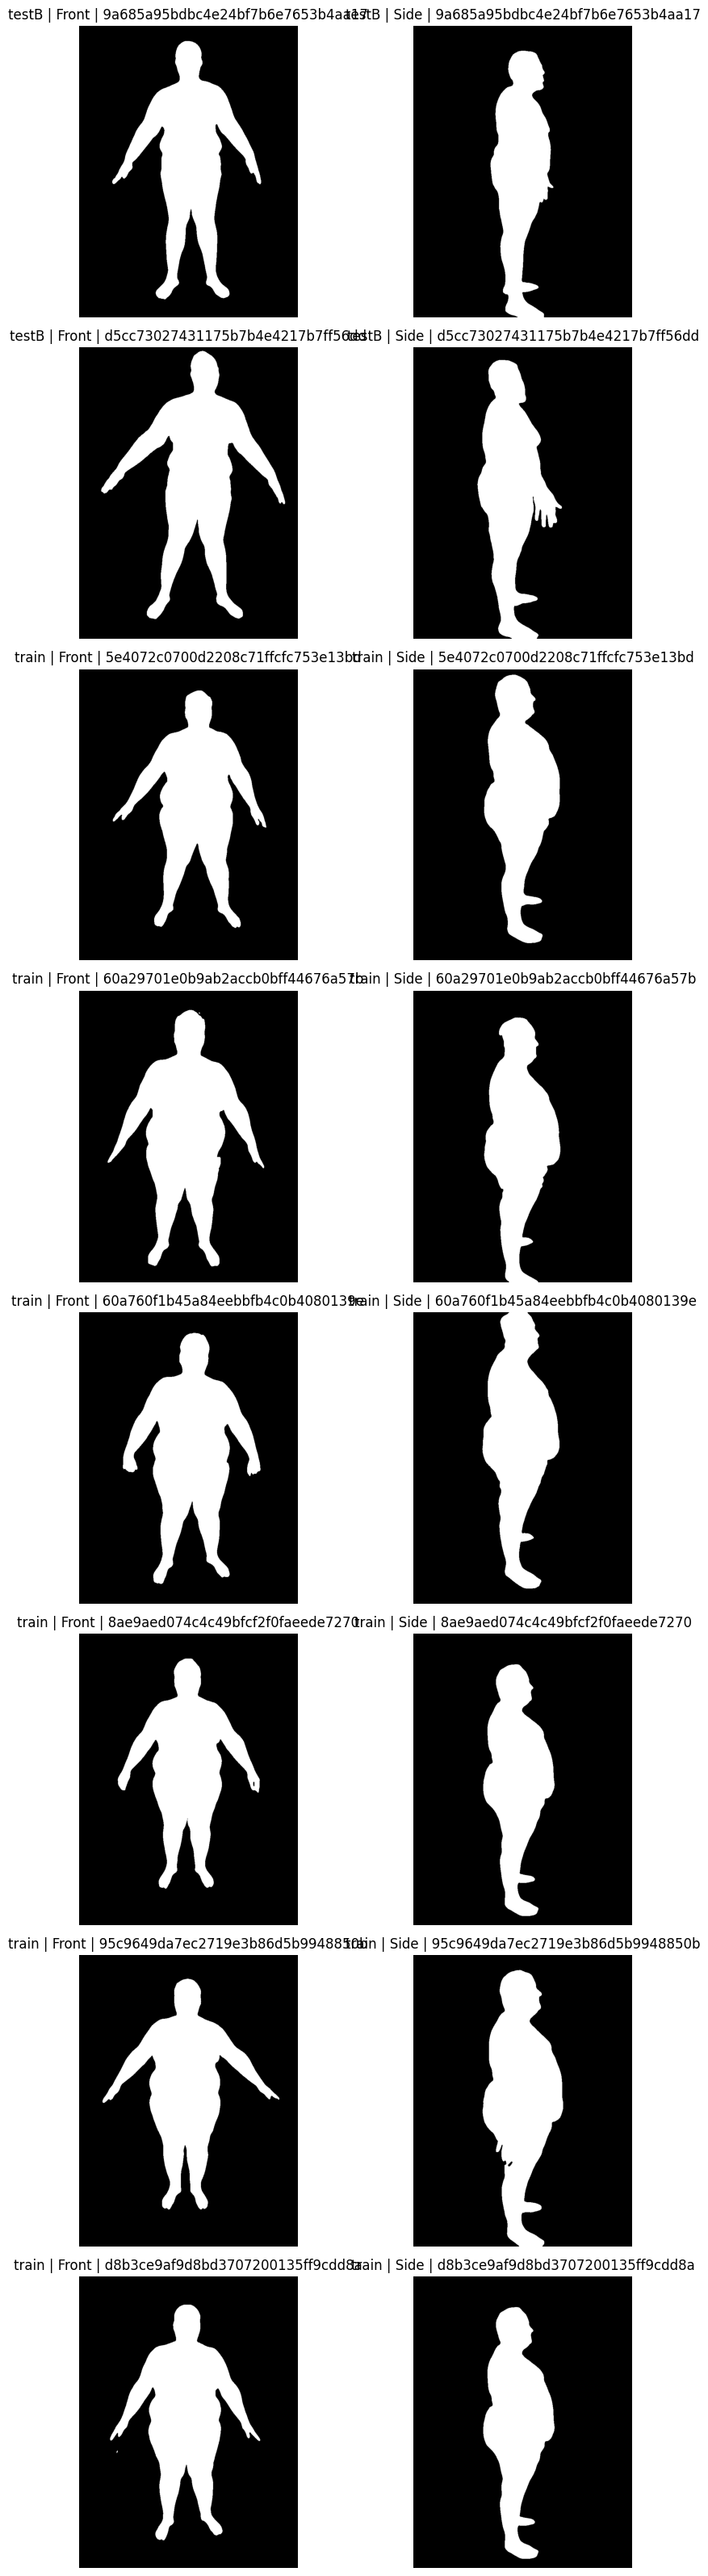


ALTERNATIVE PHOTO PAIR INSPECTION COMPLETED


In [27]:

import os
import boto3
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

BUCKET = "amazon-bodym"

subjects = [
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU"
    }
]

# --------------------------------------------------
# 2. Load image from S3
# --------------------------------------------------
def load_image(key):
    response = s3.get_object(
        Bucket=BUCKET,
        Key=key
    )
    return Image.open(
        BytesIO(response["Body"].read())
    ).convert("L")

# --------------------------------------------------
# 3. Collect alternative photo pairs
# --------------------------------------------------
all_pairs = []

for item in subjects:

    split = item["split"]
    subject_id = item["subject_id"]

    mapping_path = os.path.join(
        METADATA_DIR,
        f"{split}_subject_to_photo_map.csv"
    )

    mapping = pd.read_csv(mapping_path, dtype=str)

    photos = sorted(
        mapping.loc[
            mapping["subject_id"] == subject_id,
            "photo_id"
        ].tolist()
    )

    # Exclude the previously flagged photo
    if split == "testB":
        flagged_id = "6b25639753d2cecde54f99523f675ccc"
    else:
        flagged_id = "49e8f991af693b63836a077a636aa037"

    alternatives = [
        photo_id for photo_id in photos
        if photo_id != flagged_id
    ]

    for photo_id in alternatives:
        all_pairs.append({
            "split": split,
            "subject_id": subject_id,
            "photo_id": photo_id
        })

print("Total alternative pairs:", len(all_pairs))

# --------------------------------------------------
# 4. Display all alternative pairs
# --------------------------------------------------
fig, axes = plt.subplots(
    len(all_pairs), 2,
    figsize=(10, 4 * len(all_pairs)),
    squeeze=False
)

for idx, pair in enumerate(all_pairs):

    split = pair["split"]
    photo_id = pair["photo_id"]

    front_key = f"{split}/mask/{photo_id}.png"
    side_key = f"{split}/mask_left/{photo_id}.png"

    try:
        front = load_image(front_key)
        side = load_image(side_key)

        axes[idx][0].imshow(front, cmap="gray")
        axes[idx][0].set_title(
            f"{split} | Front | {photo_id}"
        )
        axes[idx][0].axis("off")

        axes[idx][1].imshow(side, cmap="gray")
        axes[idx][1].set_title(
            f"{split} | Side | {photo_id}"
        )
        axes[idx][1].axis("off")

        print(f"{idx + 1}. {split} | {photo_id} | LOADED")

    except Exception as e:
        axes[idx][0].axis("off")
        axes[idx][1].axis("off")
        print(f"{idx + 1}. {photo_id} | ERROR: {e}")

plt.tight_layout()
plt.show()

print("\nALTERNATIVE PHOTO PAIR INSPECTION COMPLETED")


In [28]:

import os
import pandas as pd

PROJECT_ROOT = _dj_root()
METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

# 1. Update problematic image decisions
problem_path = os.path.join(
    METADATA_DIR, "problematic_image_audit.csv"
)

problem_df = pd.read_csv(problem_path)

problem_df["decision"] = (
    "Flagged - exclude photo pair from paired-view input"
)
problem_df["removed_from_dataset"] = False

problem_df.to_csv(problem_path, index=False)

# 2. Record visually accepted alternative pairs
alternatives = [
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "photo_id": "9a685a95bdbc4e24bf7b6e7653b4aa17"
    },
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "photo_id": "d5cc73027431175b7b4e4217b7ff56dd"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "5e4072c0700d2208c71ffcfc753e13bd"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "60a29701e0b9ab2accb0bff44676a57b"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "60a760f1b45a84eebbfb4c0b4080139e"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "8ae9aed074c4c49bfcf2f0faeede7270"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "95c9649da7ec2719e3b86d5b9948850b"
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "d8b3ce9af9d8bd3707200135ff9cdd8a"
    }
]

alternative_df = pd.DataFrame(alternatives)
alternative_df["front_view_status"] = "Accept - user visually verified"
alternative_df["side_view_status"] = "Accept - user visually verified"
alternative_df["decision"] = "Accepted as alternative photo pair"

alternative_path = os.path.join(
    METADATA_DIR,
    "alternative_photo_pair_visual_review.csv"
)

alternative_df.to_csv(alternative_path, index=False)

# 3. Print verification
print("=" * 65)
print("FINAL VISUAL QC SUMMARY")
print("=" * 65)

print("Problematic masks:", len(problem_df))
print("Problematic unique photo pairs:", problem_df["photo_id"].nunique())
print("Affected subjects:", problem_df["subject_id"].nunique())
print("Accepted alternative pairs:", len(alternative_df))
print("Alternative subjects:", alternative_df["subject_id"].nunique())
print("Original images deleted: 0")

print("\nProblematic image audit:")
display(problem_df)

print("\nAccepted alternative pairs:")
display(alternative_df)

print("\nSaved files:")
print(problem_path)
print(alternative_path)

assert len(problem_df) == 3
assert problem_df["photo_id"].nunique() == 2
assert len(alternative_df) == 8
assert alternative_df["photo_id"].nunique() == 8

print("\nFINAL VISUAL QC LOG: SUCCESS")


FINAL VISUAL QC SUMMARY
Problematic masks: 3
Problematic unique photo pairs: 2
Affected subjects: 2
Accepted alternative pairs: 8
Alternative subjects: 2
Original images deleted: 0

Problematic image audit:


,split,subject_id,photo_id,view,issue,severity,decision,removed_from_dataset
0,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,6b25639753d2cecde54f99523f675ccc,front,Large detached foreground component,High,Flagged - exclude photo pair from paired-view ...,False
1,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,49e8f991af693b63836a077a636aa037,side,Large irregular foreground region,High,Flagged - exclude photo pair from paired-view ...,False
2,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,6b25639753d2cecde54f99523f675ccc,side,Detached foreground component below feet,Medium,Flagged - exclude photo pair from paired-view ...,False



Accepted alternative pairs:


,split,subject_id,photo_id,front_view_status,side_view_status,decision
0,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,9a685a95bdbc4e24bf7b6e7653b4aa17,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
1,testB,3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA,d5cc73027431175b7b4e4217b7ff56dd,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
2,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,5e4072c0700d2208c71ffcfc753e13bd,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
3,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,60a29701e0b9ab2accb0bff44676a57b,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
4,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,60a760f1b45a84eebbfb4c0b4080139e,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
5,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,8ae9aed074c4c49bfcf2f0faeede7270,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
6,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,95c9649da7ec2719e3b86d5b9948850b,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair
7,train,Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU,d8b3ce9af9d8bd3707200135ff9cdd8a,Accept - user visually verified,Accept - user visually verified,Accepted as alternative photo pair



Saved files:
/content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/metadata/problematic_image_audit.csv
/content/drive/MyDrive/DorjiBari-Research/dataset/BodyM/metadata/alternative_photo_pair_visual_review.csv

FINAL VISUAL QC LOG: SUCCESS
